# x50 データの学習とテスト予測（目的変数 Y1〜Y10、LightGBM / XGBoost）

- **作成者**: ImoZukushi
- **作成日**: 2026-10-21
- **目的**: `notebook/003_feature_engineering_x50.ipynb` が出力した前処理済みのデータで、目的変数 Y1〜Y10 ごとに
  LightGBM または XGBoost のモデルを学習し、テスト期間（2025年）を再帰予測する。学習結果・テスト結果・
  SHAP によるモデル解釈を図で確認する。評価指標は MAE。
- **入力**: `data/processed/x50/x50_train_features.csv`, `data/processed/x50/x50_test_features.csv`
  （評価用に `data/synthetic/x50/dummy_x50_test_answer.csv`）
- **出力**
  - 目的変数ごと: `outputs/experiments/x50_{モデル名}_{目的変数}/{実行日時}/`（予測・スコア・図・SHAP）
  - 全体の要約: `outputs/experiments/x50_{モデル名}_summary/{実行日時}/`（MAE の表・図・ログ）
  - MLflow（`mlruns/`）、ログファイル `outputs/logs/`
- **スクリプト版**: `scripts/train_predict_x50.py`（同じ処理を CLI で実行できる）。このノートブックは `scripts/` を
  import せず、同じ関数をノートブック内（「関数の定義」）で定義している

## リークを防ぐための決まり

| 段階 | 決まり | どこで確かめるか |
|---|---|---|
| 前処理 | 説明変数・日付の前処理は、003 で学習データだけを使って fit 済み。ここでは何も fit しない | 003 のリークの確認 |
| 入力 | テストデータに、どの目的変数（`Yk`・`Yk_raw`）も、その特徴量（`Yk_lag_*`）も無いこと | 1. 読み込み（`load_inputs`） |
| 目的変数ごとのモデル | Yk のモデルの特徴量は「Yk 自身のラグ等 + 日付 + 説明変数」だけ。他の目的変数の値は使わない（テスト期間では分からないため） | 2. 学習（`prepare`） |
| 目的変数の特徴量 | ラグ・移動平均・前日比は、学習時は過去の実測値から、検証・テスト期間は**再帰予測の中で予測値から**作り直す。学習データのCSVの値と一致すること（＝CSVの値も過去の値だけから作られている）を確かめる | 2. 学習（`prepare`） |
| CV | 日付で区切る時系列CV。各 fold は境目より前だけで学習し、境目以降を**実測値を使わずに**再帰予測して評価する（本番のテスト予測と同じ条件） | 2. の fold の期間の確認 |
| 早期終了 | early stopping に使う検証データは各 fold の検証期間だけ。テスト期間のモデルは、学習データ全体で fold の平均の木の本数で学習し直す | `modeling.trainer` / `modeling.forecasting` |
| 評価 | テストの正解ファイルは、テスト予測が終わった後の MAE の計算にだけ使う | `evaluate_test` |

In [1]:
import datetime as dt
import hashlib
import logging
import re
import shutil
import sys
import time
import warnings
from collections.abc import Sequence
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# pyproject.toml を目印にリポジトリルートを探し、src/ をimportパスに追加する
# （scripts/ の関数は import せず、このノートブック内で定義する）
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

# ipywidgets が無い環境で tqdm が出す警告（進捗バーの表示だけの問題）は出さない
warnings.filterwarnings("ignore", message="IProgress not found")

# src/ 配下のモジュール（上でパスを追加した後にimportする必要がある）
from modeling.config import ExperimentConfig  # noqa: E402
from modeling.dataset import Dataset  # noqa: E402
from modeling.experiment import ExperimentResult, prepare_dataset, run_experiment  # noqa: E402
from modeling.forecasting import ForecastCVResult  # noqa: E402
from modeling.metrics import get_metric  # noqa: E402
from modeling.tracking import MLflowTracker, NullTracker, Tracker  # noqa: E402
from util.csv_io import read_csv_auto  # noqa: E402
from util.paths import data_dir, ensure_parent_dir, get_repo_root, outputs_dir  # noqa: E402
from util.plotting import add_caption, ensure_japanese_font  # noqa: E402

pd.set_option("display.max_columns", 20)

## パラメータ

papermill で実行するときは `-p 名前 値` で上書きできる（このセルに `parameters` タグを付けている）。
リストや真偽値は `-y` で YAML として渡す。

```bash
uv run papermill notebook/004_train_predict_x50.ipynb out.ipynb --cwd notebook \
    -y "{MODEL: xgboost, TARGETS: [Y1, Y2], DETAIL_TARGET: Y2}"
```

In [2]:
MODEL = "lightgbm"  # "lightgbm" または "xgboost"
TARGETS = None  # 予測する目的変数（None なら学習データの全目的変数 Y1〜Y10）
DETAIL_TARGET = "Y1"  # 詳しい図（学習の推移・残差・SHAP など）を表示する目的変数
N_TRIALS = 0  # 目的変数ごとの Optuna の試行回数（0 ならチューニングしない）
CUTOFFS = ["2023-07-01", "2024-01-01"]  # 時系列CVの検証期間の開始日
TEST_PREDICTION = "refit_full"  # "refit_full"（全学習データで学習し直す）または "fold_mean"
USE_TRACKING = True  # MLflow に記録するか
USE_ANSWER = True  # テストの正解ファイルで MAE を計算するか
OUTPUT_ROOT = None  # 出力のルート（None なら outputs/experiments）

## 関数の定義

このノートブックは `scripts/` のモジュールを import せず、使う関数をここで定義する。CLI で同じ処理を行う
`scripts/train_predict_x50.py` にも同じ関数があり、内容は同じ（どちらかを変えるときは、もう一方も揃える）。
関数の中では `src/` のモジュール（`modeling`・`util`）を使う。

### 定数と結果の入れ物

入出力のパス・列名・CVの境目の既定値と、リークのおそれを表すエラー（`LeakageError`）、読み込んだ入力（`Inputs`）・
目的変数ごとの結果（`TargetRun`）をまとめるクラス。

In [3]:
MODELS = ("lightgbm", "xgboost")


TRAIN_PATH = data_dir() / "processed" / "x50" / "x50_train_features.csv"


TEST_PATH = data_dir() / "processed" / "x50" / "x50_test_features.csv"


ANSWER_PATH = data_dir() / "synthetic" / "x50" / "dummy_x50_test_answer.csv"


DATE_COL = "date"


RAW_SUFFIX = "_raw"  # 学習データのCSVの、元の尺度の目的変数の列名の接尾辞（`Yk_raw`）


PRED_COL = "pred"  # 目的変数ごとのテスト予測の表の、予測値の列


ACTUAL_COL = "actual"  # 同じく、正解の列（正解ファイルがある場合）


# 検証期間の開始日（時系列CVの各foldの境目）。最後の fold は学習データの最終日まで
DEFAULT_CUTOFFS = ["2023-07-01", "2024-01-01"]


MLFLOW_EXPERIMENT = "x50_forecast"


logger = logging.getLogger("train_predict_x50")


class LeakageError(ValueError):
    """入力データにリークのおそれがある場合のエラー。"""


@dataclass(frozen=True)
class TargetFeatureSpec:
    """学習データのCSVにある、1つの目的変数から作った特徴量の定義（列名から読み取る）。

    Attributes:
        target: 目的変数の列名（例: `Y1`）。
        lags: ラグ（`{target}_lag_{k}`）。
        rolling_windows: 前日までの移動平均の窓幅（`{target}_lag_1_ma_{w}`）。
        rate_of_change: 前日の前日比（`{target}_lag_1_roc_1`）があるか。
        columns: これらの列名（CSVの並び順）。
    """

    target: str
    lags: list[int]
    rolling_windows: list[int]
    rate_of_change: bool
    columns: list[str] = field(default_factory=list)


@dataclass
class Inputs:
    """読み込んで確認した入力。

    Attributes:
        train: 学習データのCSV（日付の昇順）。
        test: テストデータのCSV（日付の昇順）。
        targets: 目的変数の列名（CSVの並び順）。
        specs: 目的変数 → その目的変数の特徴量の定義。
        exog_cols: 日付の特徴量・説明変数の列（学習・テストで共通。全目的変数のモデルで使う）。
    """

    train: pd.DataFrame
    test: pd.DataFrame
    targets: list[str]
    specs: dict[str, TargetFeatureSpec]
    exog_cols: list[str]


@dataclass
class TargetRun:
    """1つの目的変数の学習・予測の結果。

    Attributes:
        target: 目的変数の列名。
        dataset: 学習用データ一式。
        result: `run_experiment` の結果。
        predictions: テスト予測（列 `date`, `pred`。正解があれば `actual` も）。
        test_mae: テストの MAE（正解が無ければNone）。
    """

    target: str
    dataset: Dataset
    result: ExperimentResult
    predictions: pd.DataFrame
    test_mae: float | None

### ログ

画面とファイルの両方にログを出す設定（`setup_logging`）、ログに出すパスをリポジトリからの相対パスにする関数（`shown`）、
入力ファイルのハッシュ（どのデータで学習したかの記録用）。

In [4]:
def setup_logging(log_path: Path, level: int = logging.INFO) -> Path:
    """画面とファイルの両方にログを出す設定をする（同じ設定を2回呼んでも重複しない）。

    Args:
        log_path: ログファイルのパス（UTF-8）。
        level: ログの出力レベル。

    Returns:
        ログファイルのパス。
    """
    ensure_parent_dir(log_path)
    root = logging.getLogger()
    root.setLevel(level)
    for handler in list(root.handlers):
        if getattr(handler, "_x50", False):
            root.removeHandler(handler)
            handler.close()
    formatter = logging.Formatter("%(asctime)s %(levelname)s %(name)s: %(message)s")
    handlers: list[logging.Handler] = [
        logging.FileHandler(log_path, encoding="utf-8"),
        logging.StreamHandler(sys.stdout),
    ]
    for handler in handlers:
        handler.setFormatter(formatter)
        handler._x50 = True  # type: ignore[attr-defined]
        root.addHandler(handler)
    # ライブラリの警告もログに残す（細かい情報ログは出さない）
    logging.captureWarnings(True)
    for name in ("matplotlib", "PIL", "shap", "urllib3", "alembic", "mlflow"):
        logging.getLogger(name).setLevel(logging.WARNING)
    return log_path


def shown(path: Path) -> str:
    """ログ・画面に出すパス（リポジトリ内ならルートからの相対パス。個人のフォルダ名を残さない）。"""
    resolved = Path(path).resolve()
    root = get_repo_root()
    return resolved.relative_to(root).as_posix() if resolved.is_relative_to(root) else str(path)


def file_digest(path: Path) -> str:
    """ファイルの SHA-256（先頭12文字）。どのデータで学習したかをログに残すために使う。"""
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]

### 読み込みとリークの確認

学習データの列から目的変数（`Yk` と `Yk_raw` の組）と、その特徴量の定義（ラグ・移動平均・前日比）を読み取り、
テストデータに目的変数やその特徴量が無いこと・学習とテストで特徴量の列が同じこと・日付が1日刻みで続いていることを
確かめる（`load_inputs`）。`model_frames` は、1つの目的変数について `prepare_dataset` に渡す表を作る
（他の目的変数の列と、CSVにある目的変数の特徴量は外す）。

In [5]:
def detect_targets(columns: Sequence[str]) -> list[str]:
    """学習データの列から目的変数を見つける（`Yk` と `Yk_raw` の両方がある列 `Yk`）。"""
    return [c for c in columns if f"{c}{RAW_SUFFIX}" in columns]


def parse_target_features(columns: Sequence[str], target: str) -> TargetFeatureSpec:
    """列名から、1つの目的変数のラグ・移動平均・前日比の定義を読み取る。

    Raises:
        ValueError: 再帰予測で作り直せない目的変数の特徴量がある場合
            （2日以上前のラグの移動平均など）、またはラグが無い場合。
    """
    lags, windows, roc, found = [], [], False, []
    prefix = f"{target}_lag_"
    for col in columns:
        if not col.startswith(prefix):
            continue
        found.append(col)
        if m := re.fullmatch(rf"{re.escape(prefix)}(\d+)", col):
            lags.append(int(m.group(1)))
        elif m := re.fullmatch(rf"{re.escape(prefix)}1_ma_(\d+)", col):
            windows.append(int(m.group(1)))
        elif col == f"{prefix}1_roc_1":
            roc = True
        else:
            raise ValueError(f"再帰予測で作り直せない目的変数の特徴量です: {col}")
    if not lags:
        raise ValueError(f"学習データに目的変数のラグ（{prefix}k）がありません")
    return TargetFeatureSpec(target, sorted(lags), sorted(windows), roc, found)


def check_daily(frame: pd.DataFrame, name: str) -> None:
    """日付が1日刻みで、重複も欠けもないことを確かめる（ラグは1行=1日の前提で作るため）。"""
    gaps = frame[DATE_COL].diff().dropna()
    if frame[DATE_COL].duplicated().any() or not (gaps == pd.Timedelta(days=1)).all():
        raise ValueError(f"{name}の日付が1日刻みになっていません（重複または欠け）")


def load_inputs(
    train_path: Path = TRAIN_PATH,
    test_path: Path = TEST_PATH,
    targets: Sequence[str] | None = None,
) -> Inputs:
    """前処理済みの学習・テストデータを読み込み、リークのおそれがないことを確かめる。

    確かめること:
        - テストデータに、どの目的変数も・目的変数から作った特徴量も無い。
        - 学習・テストで、日付の特徴量・説明変数の列が同じ。
        - どちらも1日刻みで、テストデータは学習データの最終日の翌日から始まる。

    Args:
        train_path: 学習データのCSV。
        test_path: テストデータのCSV。
        targets: 予測する目的変数（Noneなら学習データの全目的変数）。

    Raises:
        LeakageError: テストデータに目的変数（またはその特徴量）がある場合。
        ValueError: 列や日付が前提を満たさない場合。
    """
    train = read_csv_auto(train_path).sort_values(DATE_COL, kind="stable").reset_index(drop=True)
    test = read_csv_auto(test_path).sort_values(DATE_COL, kind="stable").reset_index(drop=True)
    for name, path, frame in (("学習", train_path, train), ("テスト", test_path, test)):
        logger.info(
            "%sデータ: %s（%d行 × %d列, sha256=%s）",
            name,
            path.name,
            *frame.shape,
            file_digest(path),
        )

    all_targets = detect_targets(list(train.columns))
    if not all_targets:
        raise ValueError(f"学習データに目的変数（Yk と Yk{RAW_SUFFIX} の組）がありません")
    leaked = [
        c
        for c in test.columns
        if any(c == t or c == f"{t}{RAW_SUFFIX}" or c.startswith(f"{t}_") for t in all_targets)
    ]
    if leaked:
        raise LeakageError(f"テストデータに目的変数（またはその特徴量）があります: {leaked}")
    unknown = [t for t in targets or [] if t not in all_targets]
    if unknown:
        raise ValueError(f"学習データに無い目的変数です: {unknown}（あるのは {all_targets}）")

    columns = list(train.columns)
    specs = {t: parse_target_features(columns, t) for t in all_targets}
    target_cols = {c for t in all_targets for c in (t, f"{t}{RAW_SUFFIX}", *specs[t].columns)}
    exog_cols = [c for c in columns if c != DATE_COL and c not in target_cols]
    if set(exog_cols) != set(test.columns) - {DATE_COL}:
        only_train = sorted(set(exog_cols) - set(test.columns))
        only_test = sorted(set(test.columns) - set(exog_cols) - {DATE_COL})
        raise ValueError(
            f"学習・テストで特徴量の列が違います（学習のみ: {only_train}, テストのみ: {only_test}）"
        )

    check_daily(train, "学習データ")
    check_daily(test, "テストデータ")
    train_end, test_start = train[DATE_COL].max(), test[DATE_COL].min()
    if test_start != train_end + pd.Timedelta(days=1):
        raise ValueError(
            f"テストデータが学習データの翌日から始まっていません: {train_end} → {test_start}"
        )
    selected = list(targets) if targets else all_targets
    first = specs[selected[0]]
    logger.info(
        "期間: 学習 %s〜%s / テスト %s〜%s",
        f"{train[DATE_COL].min():%Y-%m-%d}",
        f"{train_end:%Y-%m-%d}",
        f"{test_start:%Y-%m-%d}",
        f"{test[DATE_COL].max():%Y-%m-%d}",
    )
    logger.info("目的変数: %s", selected)
    logger.info(
        "特徴量（目的変数ごと）: 自身のラグ等 %d列（ラグ %s, 移動平均 %s, 前日比 %s。"
        "再帰予測で作り直す）, 日付・説明変数 %d列",
        len(first.columns),
        first.lags,
        first.rolling_windows,
        first.rate_of_change,
        len(exog_cols),
    )
    return Inputs(
        train=train,
        test=test[[DATE_COL, *exog_cols]],
        targets=selected,
        specs={t: specs[t] for t in selected},
        exog_cols=exog_cols,
    )


def model_frames(inputs: Inputs, target: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """1つの目的変数について、`prepare_dataset` に渡す学習・テストの表を作る。

    学習の表は「日付・日付の特徴量・説明変数・目的変数（元の尺度）」だけにする。
    他の目的変数の列と、CSVにある目的変数の特徴量は外す（目的変数の特徴量は `modeling` に
    同じ定義で作り直させる。テスト期間は再帰予測の中で作るため）。
    """
    train = inputs.train[[DATE_COL, *inputs.exog_cols]].assign(
        **{target: inputs.train[f"{target}{RAW_SUFFIX}"]}
    )
    test = inputs.test[[DATE_COL, *inputs.exog_cols]]
    assert target not in test.columns
    return train, test

### 実験設定

1つの目的変数・1モデル分の `modeling.config.ExperimentConfig` を作る。日付で区切る時系列CV（`time_cutoff`）、
目的変数の対数変換、再帰予測の特徴量の定義（学習データのCSVと同じもの）、SHAP・誤差評価・MLflow の設定を含む。

In [6]:
def make_config(
    model: str,
    spec: TargetFeatureSpec,
    cutoffs: Sequence[str] = DEFAULT_CUTOFFS,
    n_trials: int = 0,
    test_prediction: str = "refit_full",
    train_path: Path = TRAIN_PATH,
    test_path: Path = TEST_PATH,
) -> ExperimentConfig:
    """1つの目的変数・1モデル分の実験設定を作る（`ExperimentConfig` で検証する）。

    Args:
        model: モデル名（`lightgbm` / `xgboost`）。
        spec: 目的変数とその特徴量の定義（学習データのCSVと同じものを再帰予測でも作る）。
        cutoffs: 時系列CVの検証期間の開始日。
        n_trials: Optunaの試行回数（0ならチューニングしない）。
        test_prediction: テスト予測の作り方（`refit_full` は学習データ全体で学習し直したモデル、
            `fold_mean` は各foldのモデルの平均）。
        train_path: 記録用の学習データのパス。
        test_path: 記録用のテストデータのパス。

    Returns:
        検証済みの実験設定。

    Raises:
        ValueError: 未対応のモデル名の場合。
    """
    if model not in MODELS:
        raise ValueError(f"モデルは {MODELS} から選んでください: {model}")
    return ExperimentConfig.model_validate(
        {
            "name": f"x50_{model}_{spec.target}",
            # time_series では時間順を無視したCV（kfold 等）は設定エラーになる
            "task": "time_series",
            "data": {
                "train_path": str(train_path),
                "test_path": str(test_path),
                "target": spec.target,
                # 時刻列。学習データはこの列の昇順に並べ替えられる。モデルの特徴量からは外す
                "time_col": DATE_COL,
                "drop_cols": [DATE_COL],
            },
            # 特徴量の前処理は 003 のノートブックで学習データだけを使って済ませているため、
            # ここでは行わない
            "features": [],
            # 日付で区切る時系列CV。各 fold は「境目より前で学習し、境目以降を再帰予測して評価」する
            "cv": {"method": "time_cutoff", "time_column": DATE_COL, "cutoffs": list(cutoffs)},
            "model": {"name": model, "params": {"n_estimators": 1000}, "early_stopping_rounds": 50},
            "metrics": ["mae"],
            "test_prediction": test_prediction,
            "forecast": {
                "lags": spec.lags,
                "rolling_windows": spec.rolling_windows,
                "rate_of_change": spec.rate_of_change,
                # 目的変数は対数で学習・予測し、評価・出力の前に元の尺度に戻す
                # （003 の前処理と同じ変換）
                "target_transform": "log",
            },
            "tuning": {"enabled": n_trials > 0, "n_trials": max(n_trials, 1)},
            "explain": {"enabled": True},
            "evaluation": {"enabled": True, "training_history": True},
            "tracking": {"experiment_name": MLFLOW_EXPERIMENT},
        }
    )

### 学習と確認

- `prepare`: 学習用データ一式を作り、作り直した目的変数の特徴量がCSVの値と一致すること・他の目的変数が特徴量に
  入っていないこと・CVの学習期間が検証期間より前にあることを確かめる。
- `train_and_predict`: `modeling.experiment.run_experiment` で CV（再帰バックテスト）・テスト予測・誤差評価・SHAP を行う。
- `load_answer`・`evaluate_test`: テストの正解は、予測が終わった後の MAE の計算にだけ使う。

In [7]:
def prepare(config: ExperimentConfig, inputs: Inputs) -> Dataset:
    """1つの目的変数の学習用データ一式を作り、リークのおそれがないことを確かめる。

    確かめること:
        - 作り直した目的変数の特徴量が、学習データのCSVの値と一致する（CSVの特徴量も過去の値だけから
          作られている、かつ定義が同じ）。作り直せない先頭の行（過去の日数が足りない）は欠損になる。
        - モデルの特徴量に、他の目的変数（やその特徴量）が入っていない。
        - CVの各foldで、学習期間がすべて検証期間より前にある。
        - テストデータに目的変数が無い（再帰予測は予測値だけを履歴に足す）。

    Raises:
        LeakageError: 上のいずれかを満たさない場合。
    """
    target = config.data.target
    spec = inputs.specs[target]
    train, test = model_frames(inputs, target)
    dataset = prepare_dataset(config, train, test)

    rebuilt = dataset.X[spec.columns].reset_index(drop=True)
    original = inputs.train[spec.columns]
    comparable = rebuilt.notna()
    if not np.allclose(
        rebuilt[comparable], original[comparable], rtol=1e-9, atol=1e-9, equal_nan=True
    ):
        raise LeakageError(
            f"{target}: 作り直した目的変数の特徴量が、学習データのCSVの値と一致しません"
        )
    others = [t for t in inputs.specs if t != target]
    mixed = [c for c in dataset.X.columns if any(c == t or c.startswith(f"{t}_") for t in others)]
    if mixed:
        raise LeakageError(f"{target}: モデルの特徴量に他の目的変数があります: {mixed}")
    n_head = int((~comparable.all(axis=1)).sum())
    logger.info(
        "%s: 目的変数の特徴量はCSVの値と一致（先頭 %d行は過去の日数が足りないため欠損）",
        target,
        n_head,
    )

    dates = pd.to_datetime(train[DATE_COL])
    for i, (train_idx, valid_idx) in enumerate(dataset.folds):
        if dates.iloc[train_idx].max() >= dates.iloc[valid_idx].min():
            raise LeakageError(f"{target} fold {i}: 学習期間が検証期間より後の日を含みます")
        logger.debug(
            "%s fold %d: 学習 %s〜%s → 検証 %s〜%s",
            target,
            i,
            f"{dates.iloc[train_idx].min():%Y-%m-%d}",
            f"{dates.iloc[train_idx].max():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].min():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].max():%Y-%m-%d}",
        )
    if dataset.test_frame is None or target in dataset.test_frame.columns:
        raise LeakageError(
            f"{target}: テストデータに目的変数があります（またはテストデータがありません）"
        )
    return dataset


def log_folds(dataset: Dataset) -> None:
    """CVの各foldの期間をログに出す（全目的変数で同じ分割なので1回だけ出す）。"""
    assert dataset.frame is not None
    dates = pd.to_datetime(dataset.frame[DATE_COL])
    for i, (train_idx, valid_idx) in enumerate(dataset.folds):
        logger.info(
            "fold %d: 学習 %s〜%s（%d日）→ 検証 %s〜%s（%d日、再帰予測で評価）",
            i,
            f"{dates.iloc[train_idx].min():%Y-%m-%d}",
            f"{dates.iloc[train_idx].max():%Y-%m-%d}",
            len(train_idx),
            f"{dates.iloc[valid_idx].min():%Y-%m-%d}",
            f"{dates.iloc[valid_idx].max():%Y-%m-%d}",
            len(valid_idx),
        )


def make_tracker(enabled: bool) -> Tracker:
    """MLflow に記録する（`enabled=False` なら何も記録しない）。"""
    return MLflowTracker(MLFLOW_EXPERIMENT) if enabled else NullTracker()


def train_and_predict(
    config: ExperimentConfig,
    dataset: Dataset,
    tracker: Tracker,
    output_root: Path | None = None,
    extra_tags: dict[str, str] | None = None,
) -> ExperimentResult:
    """CV学習（再帰バックテスト）・テスト予測・誤差評価・SHAP を `run_experiment` で行う。"""
    target = config.data.target
    start = time.perf_counter()
    result = run_experiment(
        config,
        dataset,
        tracker=tracker,
        output_root=output_root or outputs_dir() / "experiments",
        extra_tags={"target": target, **(extra_tags or {})},
    )
    cv = result.cv_result
    onestep = (
        f" / 参考: 1日先予測 {cv.onestep_oof_scores['mae']:.4f}"
        if isinstance(cv, ForecastCVResult)
        else ""
    )
    logger.info(
        "%s: CV MAE（再帰予測）fold別 %s / OOF %.4f%s（%.1f秒）",
        target,
        [round(s, 4) for s in cv.fold_scores["mae"]],
        cv.oof_scores["mae"],
        onestep,
        time.perf_counter() - start,
    )
    if result.tuning_result is not None:
        logger.info(
            "%s: チューニングの最良パラメータ: %s", target, result.tuning_result.best_params
        )
    return result


def test_predictions(dataset: Dataset, result: ExperimentResult) -> pd.DataFrame:
    """テスト予測を日付つきの表にする（元の尺度）。"""
    assert dataset.test_frame is not None and result.cv_result.test_pred is not None
    return pd.DataFrame(
        {
            DATE_COL: dataset.test_frame[DATE_COL].to_numpy(),
            PRED_COL: result.cv_result.test_pred,
        }
    )


def load_answer(answer_path: Path) -> pd.DataFrame:
    """テストの正解を読む（テスト予測が終わった後の評価にだけ使う）。"""
    answer = read_csv_auto(answer_path)
    logger.info("正解: %s（%d行。評価にだけ使う）", answer_path.name, len(answer))
    return answer


def evaluate_test(
    predictions: pd.DataFrame, answer: pd.DataFrame, target: str
) -> tuple[pd.DataFrame, float]:
    """テスト予測を正解と比べ、MAE を返す。

    Returns:
        (正解の列 `actual` を付けたテスト予測, MAE)。
    """
    merged = predictions.merge(
        answer[[DATE_COL, target]].rename(columns={target: ACTUAL_COL}),
        on=DATE_COL,
        how="left",
        validate="one_to_one",
    )
    if merged[ACTUAL_COL].isna().any():
        raise ValueError(f"正解ファイルに、{target} のテスト期間の一部の日付がありません")
    mae = get_metric("mae")(merged[ACTUAL_COL].to_numpy(), merged[PRED_COL].to_numpy())
    logger.info("%s: テスト MAE %.4f（%d日）", target, mae, len(merged))
    return merged, mae

### 図（目的変数ごと）と、1つの目的変数の実行

学習結果（学習期間の実測値と検証期間の再帰予測・残差）とテスト結果（予測と実測・散布図・月別MAE）の図を作り、
目的変数ごとの出力ディレクトリと MLflow に保存する。`run_target` は、1つの目的変数について
「設定 → 確認 → 学習 → テスト予測 → 評価 → 保存」をまとめて行う。

In [8]:
def plot_training_result(dataset: Dataset, result: ExperimentResult, title: str) -> plt.Figure:
    """学習結果: 学習期間の実測値と、各 fold の検証期間の再帰予測（OOF）を重ねて描く。"""
    ensure_japanese_font()
    assert dataset.frame is not None
    cv = result.cv_result
    dates = pd.to_datetime(dataset.frame[DATE_COL]).to_numpy()
    fig, axes = plt.subplots(2, 1, figsize=(13, 8), constrained_layout=True, height_ratios=[3, 2])
    ax = axes[0]
    ax.plot(dates, dataset.y, color="black", linewidth=1, label="実測")
    mae = get_metric("mae")
    for fold in range(len(cv.fold_scores["mae"])):
        mask = cv.fold_ids == fold
        if not mask.any():
            continue
        ax.axvspan(dates[mask].min(), dates[mask].max(), color=f"C{fold}", alpha=0.08)
        ax.plot(
            dates[mask],
            cv.oof_pred[mask],
            color=f"C{fold}",
            linewidth=1.2,
            label=f"fold {fold} の再帰予測（MAE={mae(dataset.y[mask], cv.oof_pred[mask]):.2f}）",
        )
    ax.set_title(f"{title}: 学習期間の実測値と、検証期間の再帰予測")
    ax.set_ylabel(dataset_target(dataset))
    ax.legend(loc="upper left")

    # 検証期間の残差（実測 − 予測）。予測が先に進むほど誤差が広がるかを見る
    ax = axes[1]
    predicted = cv.fold_ids >= 0
    residual = dataset.y - cv.oof_pred
    for fold in np.unique(cv.fold_ids[predicted]):
        mask = cv.fold_ids == fold
        ax.plot(dates[mask], residual[mask], color=f"C{fold}", linewidth=0.8)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_ylabel("残差（実測 − 予測）")
    ax.set_xlabel("日付")
    ax.set_title("検証期間の残差")
    add_caption(
        fig,
        f"OOF MAE={cv.oof_scores['mae']:.3f}。網掛けは各 fold の検証期間。"
        "検証期間は実測値を使わず、予測値を次のラグに使う再帰予測で評価した。",
    )
    return fig


def dataset_target(dataset: Dataset) -> str:
    """学習用データ一式の目的変数名（図の軸ラベル用）。"""
    assert dataset.frame is not None
    names = [c for c in dataset.frame.columns if c not in dataset.X.columns and c != DATE_COL]
    return names[0] if names else "目的変数"


def plot_test_result(
    dataset: Dataset, predictions: pd.DataFrame, title: str, history_days: int = 180
) -> plt.Figure:
    """テスト結果: テスト期間の予測（正解があれば実測と比較）を描く。

    正解（列 `actual`）があれば、時系列・予測と実測の散布図・月別MAEの3つを描く。
    無ければ時系列だけ。
    """
    ensure_japanese_font()
    assert dataset.frame is not None
    has_answer = ACTUAL_COL in predictions.columns
    if has_answer:
        fig, axes = plt.subplot_mosaic(
            [["series", "series"], ["scatter", "monthly"]],
            figsize=(13, 9),
            constrained_layout=True,
            height_ratios=[3, 2],
        )
    else:
        fig, ax = plt.subplots(figsize=(13, 5), constrained_layout=True)
        axes = {"series": ax}
    history = dataset.frame.tail(history_days)
    ax = axes["series"]
    ax.plot(
        history[DATE_COL],
        dataset.y[-history_days:],
        color="gray",
        linewidth=1,
        label="学習期間の実測（直近）",
    )
    if has_answer:
        ax.plot(
            predictions[DATE_COL],
            predictions[ACTUAL_COL],
            color="black",
            linewidth=1,
            label="テスト期間の実測",
        )
    ax.plot(
        predictions[DATE_COL], predictions[PRED_COL], color="C3", linewidth=1.5, label="再帰予測"
    )
    ax.axvline(predictions[DATE_COL].min(), color="gray", linestyle="--", linewidth=0.8)
    period = f"{predictions[DATE_COL].min():%Y-%m-%d}〜{predictions[DATE_COL].max():%Y-%m-%d}"
    ax.set_title(f"{title}: テスト期間（{period}）の予測")
    ax.set_ylabel(dataset_target(dataset))
    ax.legend(loc="upper left")

    caption = "学習データの最終日の翌日から、予測値を次のラグに使う再帰予測で1日ずつ予測した。"
    if has_answer:
        actual, pred = predictions[ACTUAL_COL], predictions[PRED_COL]
        mae = float(np.mean(np.abs(actual - pred)))
        ax = axes["scatter"]
        ax.scatter(actual, pred, s=10, alpha=0.6)
        low, high = float(min(actual.min(), pred.min())), float(max(actual.max(), pred.max()))
        ax.plot([low, high], [low, high], color="gray", linestyle="--", linewidth=0.8)
        ax.set_xlabel("実測")
        ax.set_ylabel("予測")
        ax.set_title(f"予測と実測（MAE={mae:.3f}）")

        # 月ごとのMAE（予測が先に進むほど誤差が大きくなるか）
        monthly = (actual - pred).abs().groupby(predictions[DATE_COL].dt.to_period("M")).mean()
        ax = axes["monthly"]
        positions = np.arange(len(monthly))
        ax.bar(positions, monthly.to_numpy(), color="C0")
        ax.set_xticks(positions, [str(p) for p in monthly.index])
        ax.set_ylim(bottom=0)  # 棒グラフは0起点
        ax.set_ylabel("MAE")
        ax.set_title("月別のMAE")
        ax.tick_params(axis="x", rotation=60)
        caption += f" テスト MAE={mae:.3f}（正解は予測後の評価にだけ使用）。"
    add_caption(fig, caption)
    return fig


def save_figure(fig: plt.Figure, path: Path) -> Path:
    """図を保存して閉じる。"""
    fig.savefig(ensure_parent_dir(path), dpi=150, bbox_inches="tight")
    plt.close(fig)
    logger.info("図を保存: %s", shown(path))
    return path


def save_target_outputs(run: TargetRun) -> list[Path]:
    """1つの目的変数のテスト予測・スコア・図を実験の出力ディレクトリに保存し、MLflowにも記録する。"""
    out = run.result.output_dir
    title = out.parent.name
    paths = [ensure_parent_dir(out / "test_predictions.csv")]
    run.predictions.to_csv(paths[0], index=False, date_format="%Y-%m-%d")
    if run.test_mae is not None:
        paths.append(out / "test_scores.csv")
        scores = pd.DataFrame(
            {"metric": ["mae"], "value": [run.test_mae], "n": [len(run.predictions)]}
        )
        scores.to_csv(paths[-1], index=False)
    figures = out / "figures"
    training = plot_training_result(run.dataset, run.result, title)
    paths.append(save_figure(training, figures / "training_result.png"))
    test = plot_test_result(run.dataset, run.predictions, title)
    paths.append(save_figure(test, figures / "test_result.png"))
    # run_experiment のrun（終了済み）に、テストの指標と追加の出力を記録する
    if run.result.run_id is not None:
        import mlflow

        client = mlflow.tracking.MlflowClient()
        if run.test_mae is not None:
            client.log_metric(run.result.run_id, "test_mae", run.test_mae)
        for path in paths:
            artifact_path = "test" if path.suffix == ".csv" else "figures"
            client.log_artifact(run.result.run_id, str(path), artifact_path=artifact_path)
    return paths


def run_target(
    model: str,
    target: str,
    inputs: Inputs,
    tracker: Tracker,
    answer: pd.DataFrame | None = None,
    cutoffs: Sequence[str] = DEFAULT_CUTOFFS,
    n_trials: int = 0,
    test_prediction: str = "refit_full",
    output_root: Path | None = None,
    batch: str | None = None,
) -> TargetRun:
    """1つの目的変数について、設定・確認・学習・テスト予測・評価・出力の保存までを行う。

    Args:
        model: モデル名。
        target: 目的変数。
        inputs: `load_inputs` の結果。
        tracker: 実験ログの記録先。
        answer: テストの正解（Noneなら評価しない）。予測が終わった後にだけ使う。
        cutoffs: 時系列CVの検証期間の開始日。
        n_trials: Optunaの試行回数（0ならチューニングしない）。
        test_prediction: テスト予測の作り方。
        output_root: 出力のルート（Noneなら `outputs/experiments`）。
        batch: 同じ実行の run を結び付ける MLflow のタグ。

    Returns:
        結果。
    """
    config = make_config(model, inputs.specs[target], cutoffs, n_trials, test_prediction)
    dataset = prepare(config, inputs)
    result = train_and_predict(
        config, dataset, tracker, output_root, extra_tags={"batch": batch} if batch else None
    )
    predictions = test_predictions(dataset, result)
    test_mae = None
    if answer is not None:
        predictions, test_mae = evaluate_test(predictions, answer, target)
    run = TargetRun(target, dataset, result, predictions, test_mae)
    save_target_outputs(run)
    return run

### 全目的変数の要約

目的変数ごとの MAE・相対MAE の表、全目的変数のテスト予測、目的変数ごとの SHAP 重要度の比較を作り、
要約の図とともに保存して MLflow に要約の run として記録する（`save_summary`）。

In [9]:
def summary_frame(runs: Sequence[TargetRun]) -> pd.DataFrame:
    """目的変数ごとの MAE をまとめた表。

    目的変数ごとに尺度が違うため、MAE を実測値の平均で割った相対MAE も載せる
    （CV は検証期間の実測、テストはテスト期間の実測の平均で割る）。
    """
    rows = []
    for run in runs:
        cv = run.result.cv_result
        predicted = cv.fold_ids >= 0
        row: dict[str, object] = {
            "target": run.target,
            "cv_oof_mae": cv.oof_scores["mae"],
            "cv_relative_mae": cv.oof_scores["mae"] / float(np.mean(run.dataset.y[predicted])),
        }
        if isinstance(cv, ForecastCVResult):
            row["cv_onestep_mae"] = cv.onestep_oof_scores["mae"]
        if run.test_mae is not None:
            row["test_mae"] = run.test_mae
            row["test_relative_mae"] = run.test_mae / float(run.predictions[ACTUAL_COL].mean())
        row["output_dir"] = shown(run.result.output_dir)
        row["run_id"] = run.result.run_id
        rows.append(row)
    return pd.DataFrame(rows)


def wide_predictions(runs: Sequence[TargetRun]) -> pd.DataFrame:
    """全目的変数のテスト予測を横に並べた表（列 `date`, `Yk_pred`, 正解があれば `Yk_actual`）。"""
    frame = runs[0].predictions[[DATE_COL]].copy()
    for run in runs:
        frame[f"{run.target}_pred"] = run.predictions[PRED_COL].to_numpy()
        if ACTUAL_COL in run.predictions.columns:
            frame[f"{run.target}_actual"] = run.predictions[ACTUAL_COL].to_numpy()
    return frame


def plot_summary_mae(summary: pd.DataFrame, title: str) -> plt.Figure:
    """目的変数ごとの相対MAE（CV とテスト）の棒グラフ。"""
    ensure_japanese_font()
    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    positions = np.arange(len(summary))
    has_test = "test_relative_mae" in summary.columns
    width = 0.4 if has_test else 0.6
    ax.bar(
        positions - (width / 2 if has_test else 0),
        summary["cv_relative_mae"],
        width,
        label="CV（検証期間の再帰予測）",
    )
    if has_test:
        ax.bar(positions + width / 2, summary["test_relative_mae"], width, label="テスト（2025年）")
    ax.set_xticks(positions, summary["target"])
    ax.set_ylim(bottom=0)  # 棒グラフは0起点
    ax.set_ylabel("相対MAE（MAE ÷ 実測値の平均）")
    ax.set_title(f"{title}: 目的変数ごとの誤差")
    ax.legend(loc="upper left")
    add_caption(
        fig,
        "目的変数ごとに水準が違うため、MAE を実測値の平均で割って比べる。"
        "CV とテストの差が大きい目的変数は、期間によって当てやすさが違う（過学習・トレンドなど）。",
    )
    return fig


def plot_test_overview(runs: Sequence[TargetRun], title: str, ncols: int = 2) -> plt.Figure:
    """全目的変数のテスト期間の予測（正解があれば実測も）を並べて描く。"""
    ensure_japanese_font()
    nrows = int(np.ceil(len(runs) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(14, 2.6 * nrows), constrained_layout=True, sharex=True, squeeze=False
    )
    for ax, run in zip(axes.flat, runs, strict=False):
        p = run.predictions
        if ACTUAL_COL in p.columns:
            ax.plot(p[DATE_COL], p[ACTUAL_COL], color="black", linewidth=0.8, label="実測")
        ax.plot(p[DATE_COL], p[PRED_COL], color="C3", linewidth=1.2, label="再帰予測")
        label = run.target if run.test_mae is None else f"{run.target}（MAE={run.test_mae:.2f}）"
        ax.set_title(label)
    for ax in list(axes.flat)[len(runs) :]:
        ax.set_visible(False)
    axes.flat[0].legend(loc="upper left")
    fig.suptitle(f"{title}: テスト期間の予測（目的変数ごと）")
    return fig


def shap_importance_table(runs: Sequence[TargetRun]) -> pd.DataFrame:
    """目的変数ごとの SHAP 重要度（平均|SHAP値|の割合）を、特徴量 × 目的変数の表にする。

    目的変数自身のラグ等は、目的変数によらず同じ行に並ぶよう `Yk_lag_1` → `自身_lag_1` に
    名前を揃える。
    重要度は目的変数ごとに合計1になるよう割合にする（目的変数によって尺度が違うため）。
    """
    columns = {}
    for run in runs:
        path = run.result.output_dir / "shap" / "shap_importance.csv"
        importance = pd.read_csv(path).set_index("feature")["mean_abs_shap"]
        importance.index = [
            f"自身{name[len(run.target) :]}" if name.startswith(f"{run.target}_") else name
            for name in importance.index
        ]
        columns[run.target] = importance / importance.sum()
    return pd.DataFrame(columns).fillna(0.0)


def plot_shap_overview(table: pd.DataFrame, title: str, top_k: int = 15) -> plt.Figure:
    """SHAP 重要度の割合を、上位の特徴量 × 目的変数のヒートマップで描く。"""
    ensure_japanese_font()
    top = table.loc[table.mean(axis=1).sort_values(ascending=False).index[:top_k]]
    fig, ax = plt.subplots(
        figsize=(1.0 * top.shape[1] + 4, 0.4 * top_k + 2), constrained_layout=True
    )
    image = ax.imshow(top.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(top.shape[1]), top.columns)
    ax.set_yticks(range(top.shape[0]), top.index)
    for i in range(top.shape[0]):
        for j in range(top.shape[1]):
            value = top.iat[i, j]
            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if value < top.to_numpy().max() * 0.6 else "black",
            )
    fig.colorbar(image, ax=ax, label="重要度の割合（平均|SHAP値|。目的変数ごとに合計1）")
    ax.set_title(f"{title}: 目的変数ごとの SHAP 重要度（上位{top_k}特徴量）")
    add_caption(fig, "「自身_lag_1」などは、各目的変数自身のラグ・移動平均・前日比。")
    return fig


def save_summary(
    runs: Sequence[TargetRun],
    model: str,
    summary_dir: Path,
    tracker: Tracker,
    log_path: Path | None = None,
    batch: str | None = None,
) -> pd.DataFrame:
    """全目的変数の要約（表・図・ログ）を保存し、MLflow に要約の run として記録する。"""
    title = f"x50_{model}"
    summary = summary_frame(runs)
    paths = [ensure_parent_dir(summary_dir / "summary.csv")]
    summary.to_csv(paths[0], index=False)
    paths.append(summary_dir / "test_predictions.csv")
    wide_predictions(runs).to_csv(paths[-1], index=False, date_format="%Y-%m-%d")
    paths.append(summary_dir / "shap_importance_by_target.csv")
    shap_table = shap_importance_table(runs)
    shap_table.to_csv(paths[-1], index_label="feature")
    figures = summary_dir / "figures"
    paths.append(save_figure(plot_summary_mae(summary, title), figures / "summary_mae.png"))
    paths.append(save_figure(plot_test_overview(runs, title), figures / "test_overview.png"))
    paths.append(save_figure(plot_shap_overview(shap_table, title), figures / "shap_overview.png"))

    mean_cv = float(summary["cv_relative_mae"].mean())
    message = f"要約: CV 相対MAE の平均 {mean_cv:.4f}"
    if "test_relative_mae" in summary.columns:
        message += f" / テスト 相対MAE の平均 {float(summary['test_relative_mae'].mean()):.4f}"
    logger.info("%s（%d目的変数）。表: %s", message, len(runs), shown(paths[0]))
    if log_path is not None:
        for handler in logging.getLogger().handlers:
            handler.flush()
        paths.append(Path(shutil.copy(log_path, summary_dir / "run.log")))

    tags = {"type": "summary", "model": model, **({"batch": batch} if batch else {})}
    with tracker.start_run(run_name=f"{title}_summary", tags=tags):
        tracker.log_params({"model": model, "targets": [r.target for r in runs]})
        metrics = {"mean_cv_relative_mae": mean_cv}
        for row in summary.to_dict("records"):
            metrics[f"cv_oof_mae_{row['target']}"] = row["cv_oof_mae"]
            if "test_mae" in row:
                metrics[f"test_mae_{row['target']}"] = row["test_mae"]
        if "test_relative_mae" in summary.columns:
            metrics["mean_test_relative_mae"] = float(summary["test_relative_mae"].mean())
        tracker.log_metrics(metrics)
        for path in paths:
            tracker.log_artifact(path)
        run_id = tracker.active_run_id()
    if run_id is not None:
        logger.info("MLflow に要約を記録: run_id=%s（batch=%s）", run_id, batch)
    return summary

In [10]:
# ログを画面とファイルの両方に出す
stamp = dt.datetime.now().strftime("%Y%m%d_%H%M%S")
log_name = f"train_predict_x50_{MODEL}_{stamp}_notebook.log"
log_path = setup_logging(outputs_dir() / "logs" / log_name)
output_root = None if OUTPUT_ROOT is None else Path(OUTPUT_ROOT)
batch = f"x50_{MODEL}_{stamp}"  # 同じ実行の MLflow の run に付けるタグ
print(f"ログ: {shown(log_path)}")

ログ: outputs/logs/train_predict_x50_lightgbm_20261021_221125_notebook.log


## 1. 読み込みとリークの確認

テストデータに目的変数やその特徴量が無いこと、学習・テストで特徴量の列が同じこと、日付が1日刻みで
テストデータが学習データの翌日から始まることを確かめる（満たさなければエラーで止まる）。

In [11]:
inputs = load_inputs(targets=TARGETS)
if DETAIL_TARGET not in inputs.targets:
    raise ValueError(f"DETAIL_TARGET は {inputs.targets} から選んでください: {DETAIL_TARGET}")
tracker = make_tracker(USE_TRACKING)
# 正解はここで読むが、使うのは各目的変数のテスト予測が終わった後の評価だけ
answer = load_answer(ANSWER_PATH) if USE_ANSWER and ANSWER_PATH.is_file() else None
print(f"目的変数: {inputs.targets}")
inputs.train[[DATE_COL, *[f"{t}{RAW_SUFFIX}" for t in inputs.targets]]].describe().round(2)

2026-10-21 22:11:25,306 INFO train_predict_x50: 学習データ: x50_train_features.csv（1068行 × 171列, sha256=4b32c534baae）


2026-10-21 22:11:25,308 INFO train_predict_x50: テストデータ: x50_test_features.csv（365行 × 61列, sha256=cfca97fe47f5）


2026-10-21 22:11:25,311 INFO train_predict_x50: 期間: 学習 2022-01-29〜2024-12-31 / テスト 2025-01-01〜2025-12-31


2026-10-21 22:11:25,312 INFO train_predict_x50: 目的変数: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']


2026-10-21 22:11:25,312 INFO train_predict_x50: 特徴量（目的変数ごと）: 自身のラグ等 9列（ラグ [1, 2, 3, 7, 14, 28], 移動平均 [7, 28], 前日比 True。再帰予測で作り直す）, 日付・説明変数 60列


2026-10-21 22:11:28,200 INFO train_predict_x50: 正解: dummy_x50_test_answer.csv（365行。評価にだけ使う）


目的変数: ['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Y10']


,date,Y1_raw,Y2_raw,Y3_raw,Y4_raw,Y5_raw,Y6_raw,Y7_raw,Y8_raw,Y9_raw,Y10_raw
count,1068,1068.00,1068.00,1068.00,1068.00,1068.00,1068.00,1068.00,1068.00,1068.00,1068.00
mean,2023-07-16 12:00:00,59.66,86.15,79.97,30.20,77.97,150.46,174.44,186.06,140.78,33.86
min,2022-01-29 00:00:00,21.32,46.13,45.29,19.39,46.62,72.83,111.80,98.79,69.63,18.44
25%,2022-10-22 18:00:00,49.16,77.49,70.82,27.32,69.66,129.56,159.36,157.54,123.88,29.32
50%,2023-07-16 12:00:00,59.56,85.88,80.26,30.07,77.37,149.92,174.03,186.80,141.16,33.84
75%,2024-04-08 06:00:00,70.10,95.61,88.83,33.22,85.97,173.17,189.31,213.32,158.93,38.35
max,2024-12-31 00:00:00,97.40,132.19,111.54,40.90,123.19,223.38,232.21,277.43,214.24,50.75
std,NaN,13.45,13.81,12.03,3.71,12.56,29.19,21.48,36.46,25.22,5.87


## 2. 目的変数ごとの学習とテスト予測

目的変数ごとに `run_target` で次をまとめて行う（中では `modeling.experiment.run_experiment` を使う）。

1. 実験設定を作り、学習用データ一式を作ってリークの確認をする（`prepare`）
2. CV: 各 fold で1日先予測のモデルを学習し、検証期間を再帰予測して MAE を計算する
3. テスト予測: 学習データ全体で学習し直したモデル（`refit_full`）で、2025年を再帰予測する
4. 誤差評価の図・SHAP の計算と図、MLflow への記録
5. テストの MAE（正解がある場合）と、学習結果・テスト結果の図の保存

In [12]:
runs = []
for i, target in enumerate(inputs.targets):
    print(f"=== {target}（{i + 1}/{len(inputs.targets)}） ===")
    run = run_target(
        MODEL,
        target,
        inputs,
        tracker,
        answer=answer,
        cutoffs=CUTOFFS,
        n_trials=N_TRIALS,
        test_prediction=TEST_PREDICTION,
        output_root=output_root,
        batch=batch,
    )
    if i == 0:
        log_folds(run.dataset)
    runs.append(run)

=== Y1（1/10） ===
2026-10-21 22:11:28,270 INFO train_predict_x50: Y1: 目的変数の特徴量はCSVの値と一致（先頭 28行は過去の日数が足りないため欠損）


2026-10-21 22:12:01,396 INFO train_predict_x50: Y1: CV MAE（再帰予測）fold別 [3.3882, 6.2223] / OOF 5.2742 / 参考: 1日先予測 2.9849（33.1秒）


2026-10-21 22:12:01,402 INFO train_predict_x50: Y1: テスト MAE 3.5630（365日）


2026-10-21 22:12:01,759 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_Y1/20261021_221128_273772/figures/training_result.png


2026-10-21 22:12:02,302 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_Y1/20261021_221128_273772/figures/test_result.png


...

=== Y10（10/10） ===
2026-10-21 22:16:58,733 INFO train_predict_x50: Y10: 目的変数の特徴量はCSVの値と一致（先頭 28行は過去の日数が足りないため欠損）


2026-10-21 22:17:33,677 INFO train_predict_x50: Y10: CV MAE（再帰予測）fold別 [2.3521, 2.0086] / OOF 2.1235 / 参考: 1日先予測 1.3422（34.9秒）


2026-10-21 22:17:33,681 INFO train_predict_x50: Y10: テスト MAE 1.6536（365日）


2026-10-21 22:17:34,036 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_Y10/20261021_221658_736184/figures/training_result.png


2026-10-21 22:17:34,434 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_Y10/20261021_221658_736184/figures/test_result.png


## 3. 全目的変数の結果

目的変数ごとの MAE。目的変数ごとに水準が違うため、MAE を実測値の平均で割った相対MAE も載せる。
`cv_onestep_mae` は、真のラグを使う1日先予測の MAE（再帰予測との差が、予測値をラグに使うことによる誤差の蓄積分）。

In [13]:
root = output_root or outputs_dir() / "experiments"
summary_dir = root / f"x50_{MODEL}_summary" / stamp
summary = save_summary(runs, MODEL, summary_dir, tracker, log_path, batch)
print(f"要約: {shown(summary_dir)}")
summary.drop(columns=["output_dir", "run_id"]).round(4)

2026-10-21 22:17:34,737 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_summary/20261021_221125/figures/summary_mae.png


2026-10-21 22:17:35,659 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_summary/20261021_221125/figures/test_overview.png


2026-10-21 22:17:36,154 INFO train_predict_x50: 図を保存: outputs/experiments/x50_lightgbm_summary/20261021_221125/figures/shap_overview.png


2026-10-21 22:17:36,155 INFO train_predict_x50: 要約: CV 相対MAE の平均 0.0709 / テスト 相対MAE の平均 0.0746（10目的変数）。表: outputs/experiments/x50_lightgbm_summary/20261021_221125/summary.csv


2026-10-21 22:17:36,343 INFO train_predict_x50: MLflow に要約を記録: run_id=fbab8ac9bb5f4c80b60493db847ad386（batch=x50_lightgbm_20261021_221125）


要約: outputs/experiments/x50_lightgbm_summary/20261021_221125


,target,cv_oof_mae,cv_relative_mae,cv_onestep_mae,test_mae,test_relative_mae
0,Y1,5.2742,0.0825,2.9849,3.5630,0.0495
1,Y2,5.3853,0.0675,4.5175,4.6895,0.0646
2,Y3,8.5789,0.1028,2.9890,21.4658,0.2472
3,Y4,1.2727,0.0406,1.0489,1.2102,0.0389
4,Y5,5.6401,0.0704,2.8834,6.5335,0.0804
5,Y6,15.5010,0.0930,9.2781,10.6105,0.0585
6,Y7,8.4982,0.0461,7.4796,8.4586,0.0431
7,Y8,11.5587,0.0638,7.6581,10.1859,0.0512
8,Y9,12.6234,0.0822,9.1899,10.6320,0.0629
9,Y10,2.1235,0.0600,1.3422,1.6536,0.0500


- **目的変数ごとの誤差:** CV（検証期間の再帰予測）とテスト（2025年）の相対MAE。CV とテストの差が大きい目的変数は、
  期間によって当てやすさが違う（トレンドで学習範囲の外の水準になる、など）。
- **テスト期間の予測:** 全目的変数の予測（赤）と実測（黒）。

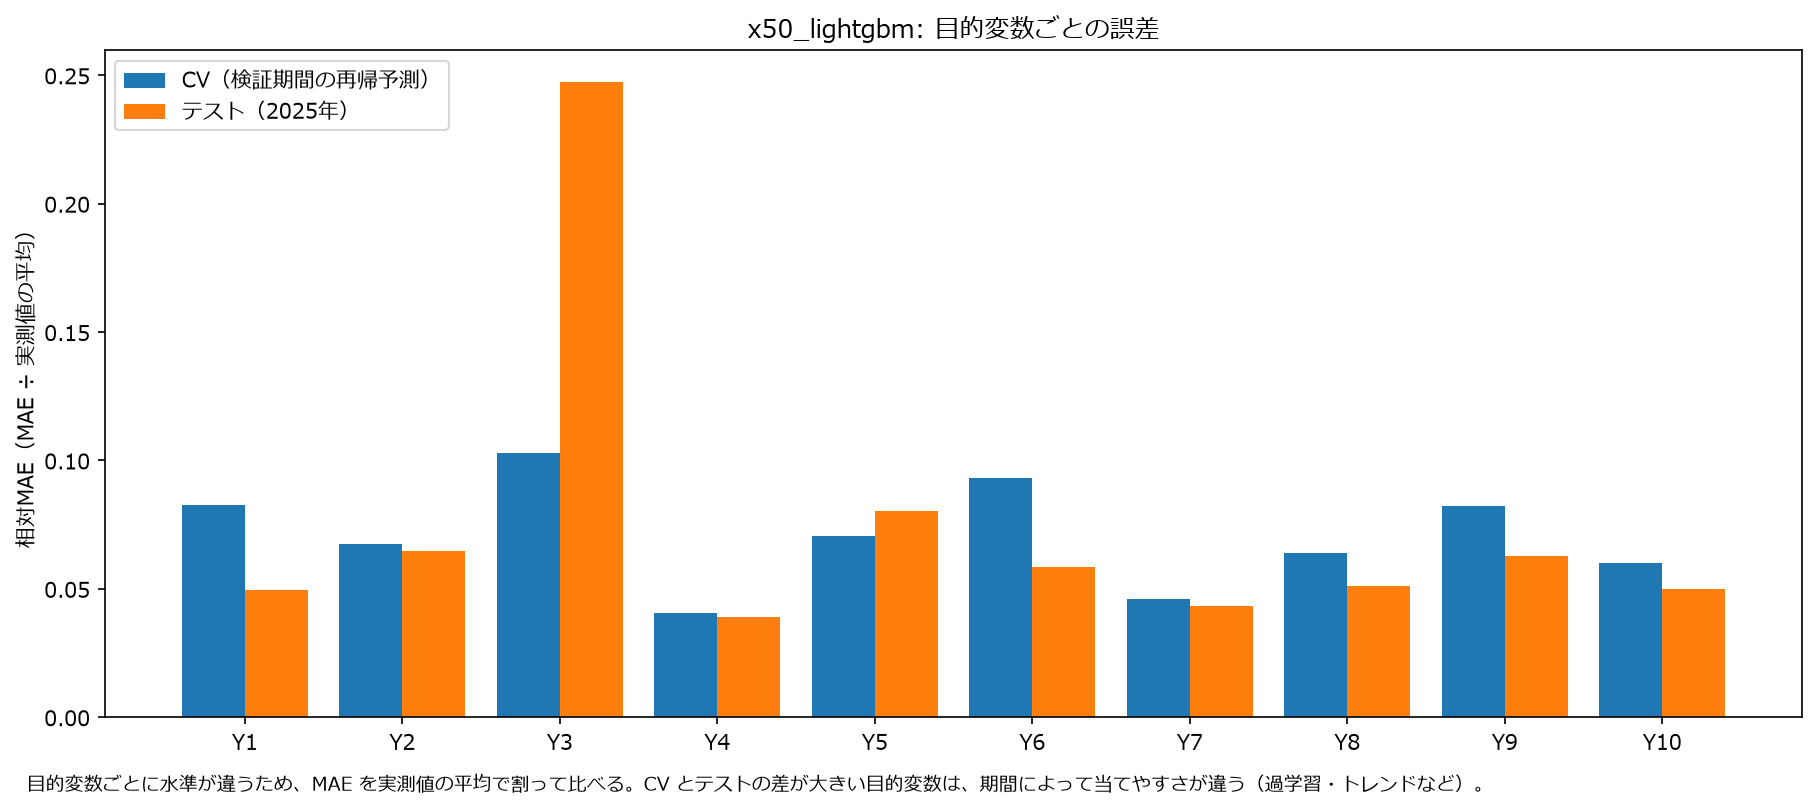

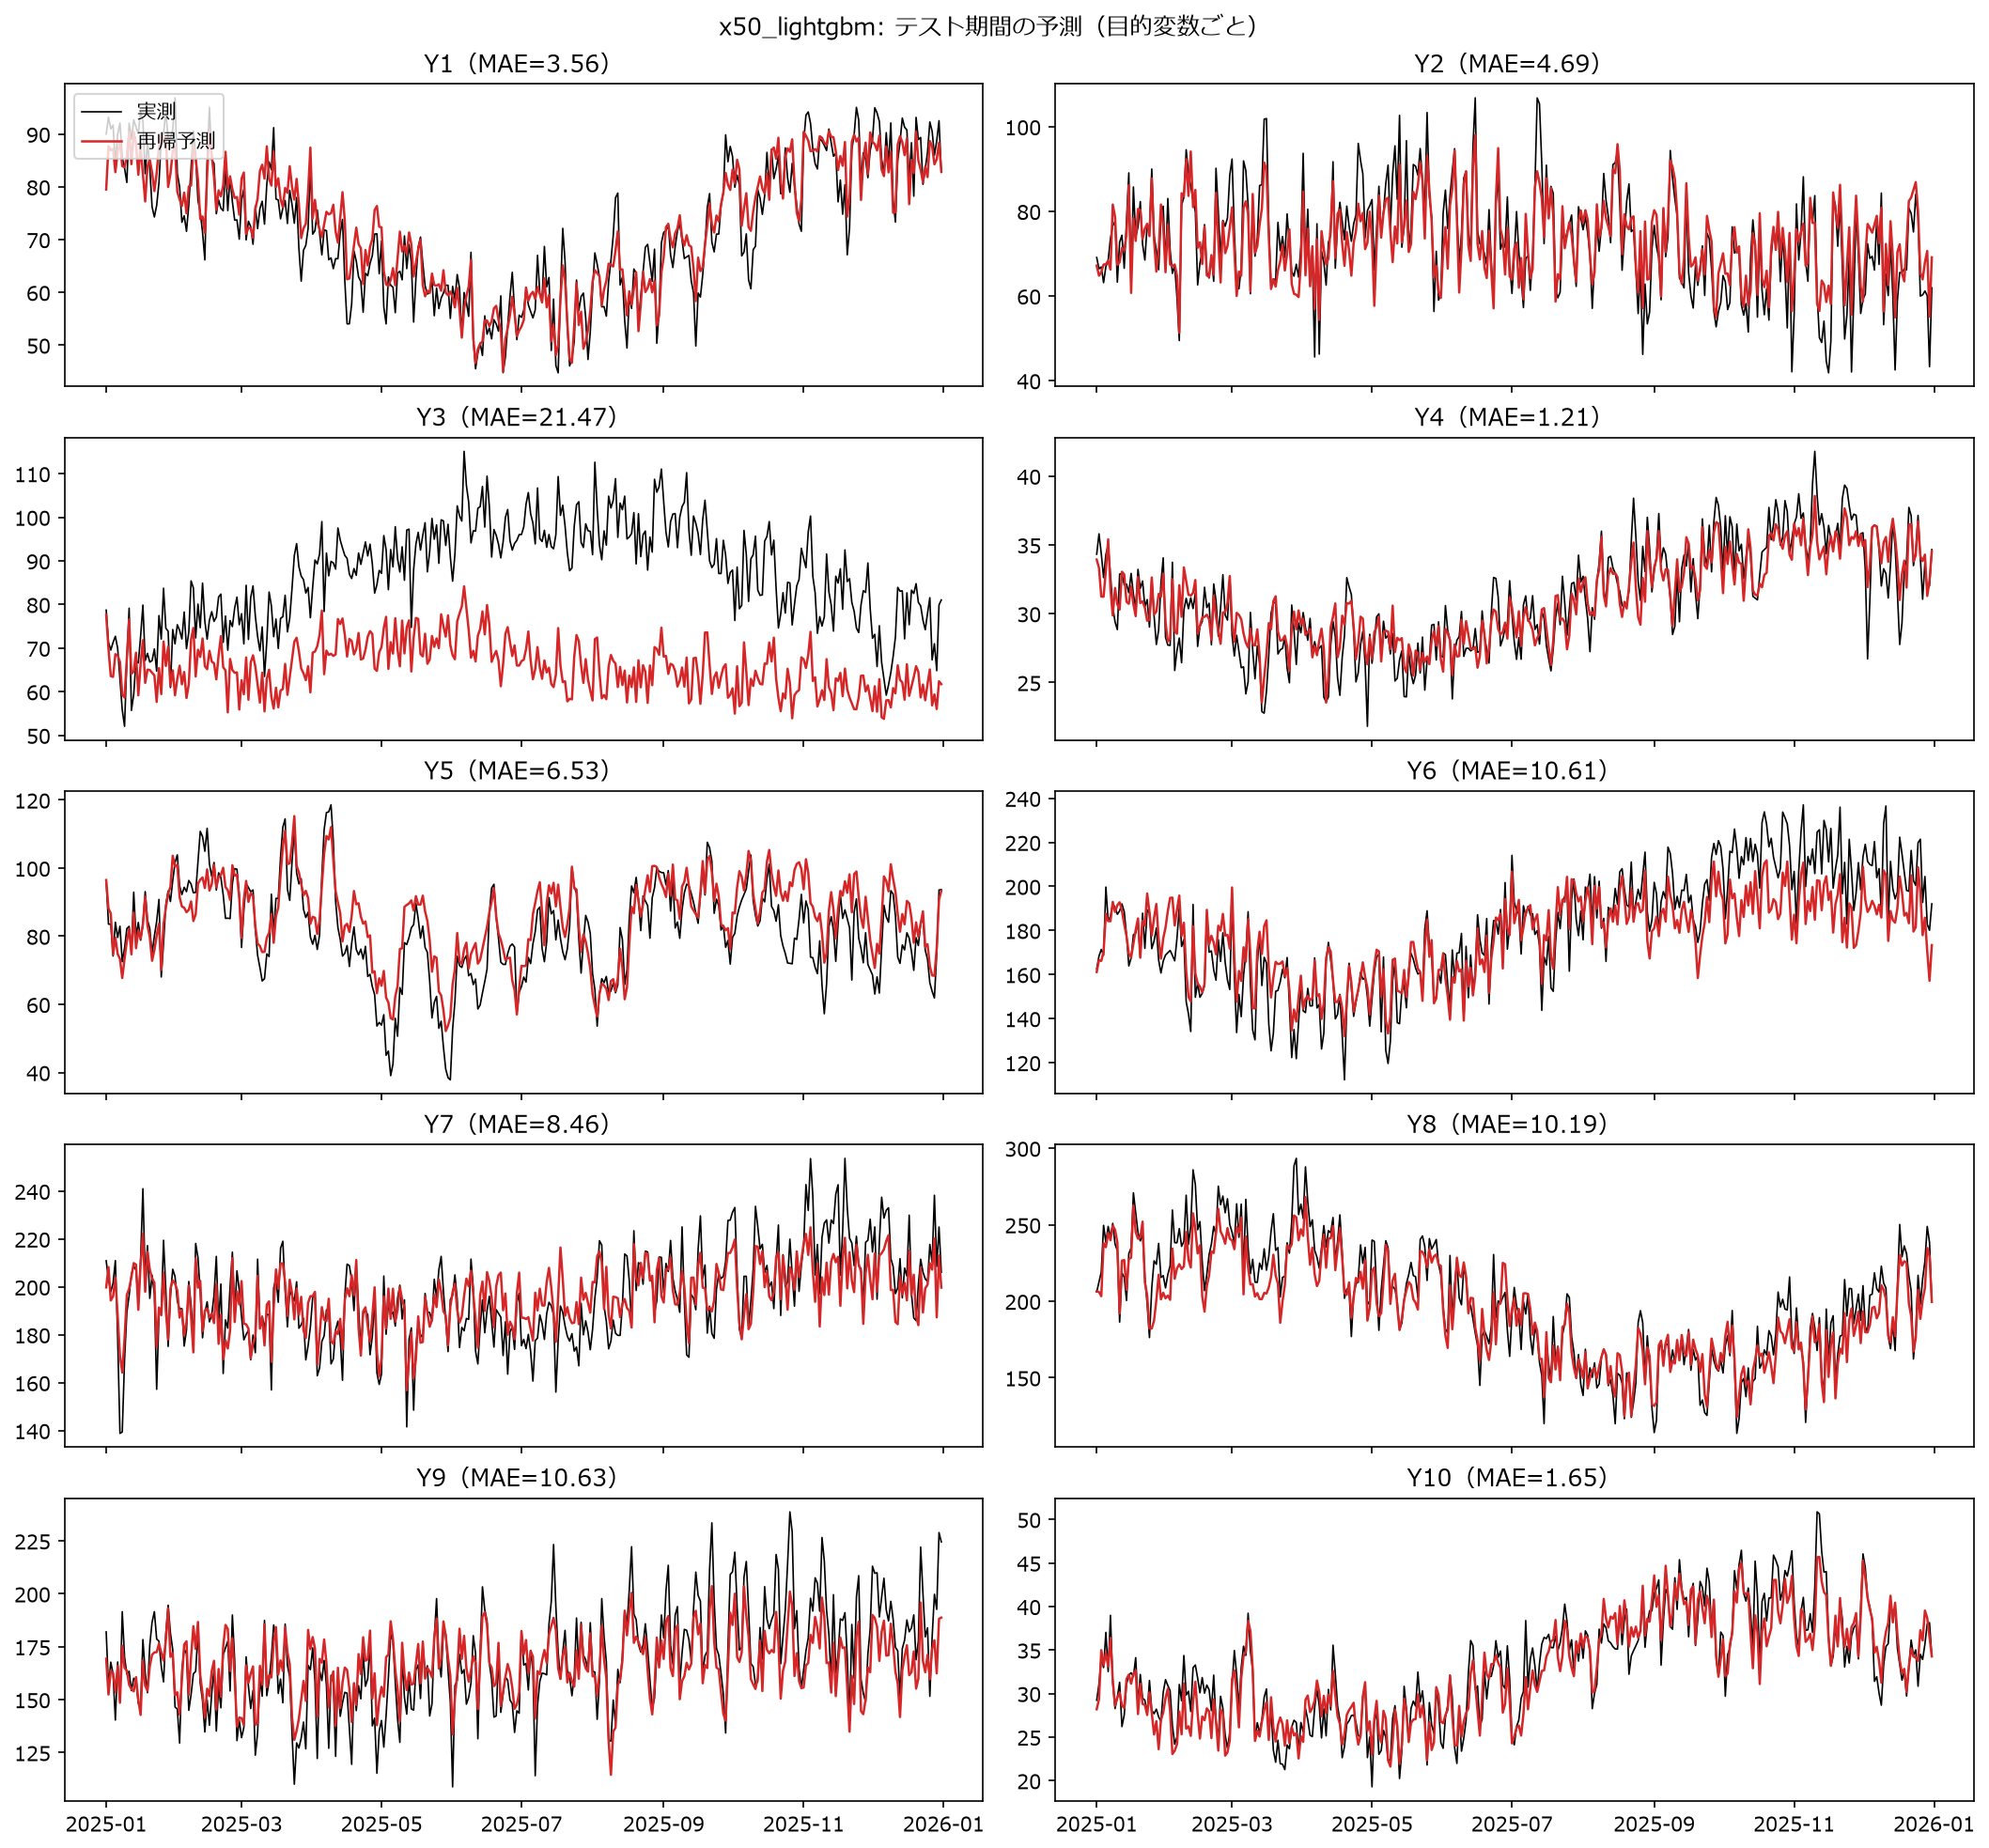

In [14]:
figures = summary_dir / "figures"
display(Image(filename=str(figures / "summary_mae.png"), width=950))
display(Image(filename=str(figures / "test_overview.png"), width=1000))

## 4. SHAP によるモデル解釈（全目的変数）

目的変数ごとの SHAP 重要度（平均 |SHAP 値|）を、目的変数ごとに合計1の割合にして並べる。
各目的変数自身のラグ・移動平均・前日比は「自身_lag_1」などにまとめて表示する。どの説明変数がどの目的変数に
効いているかを比べられる。

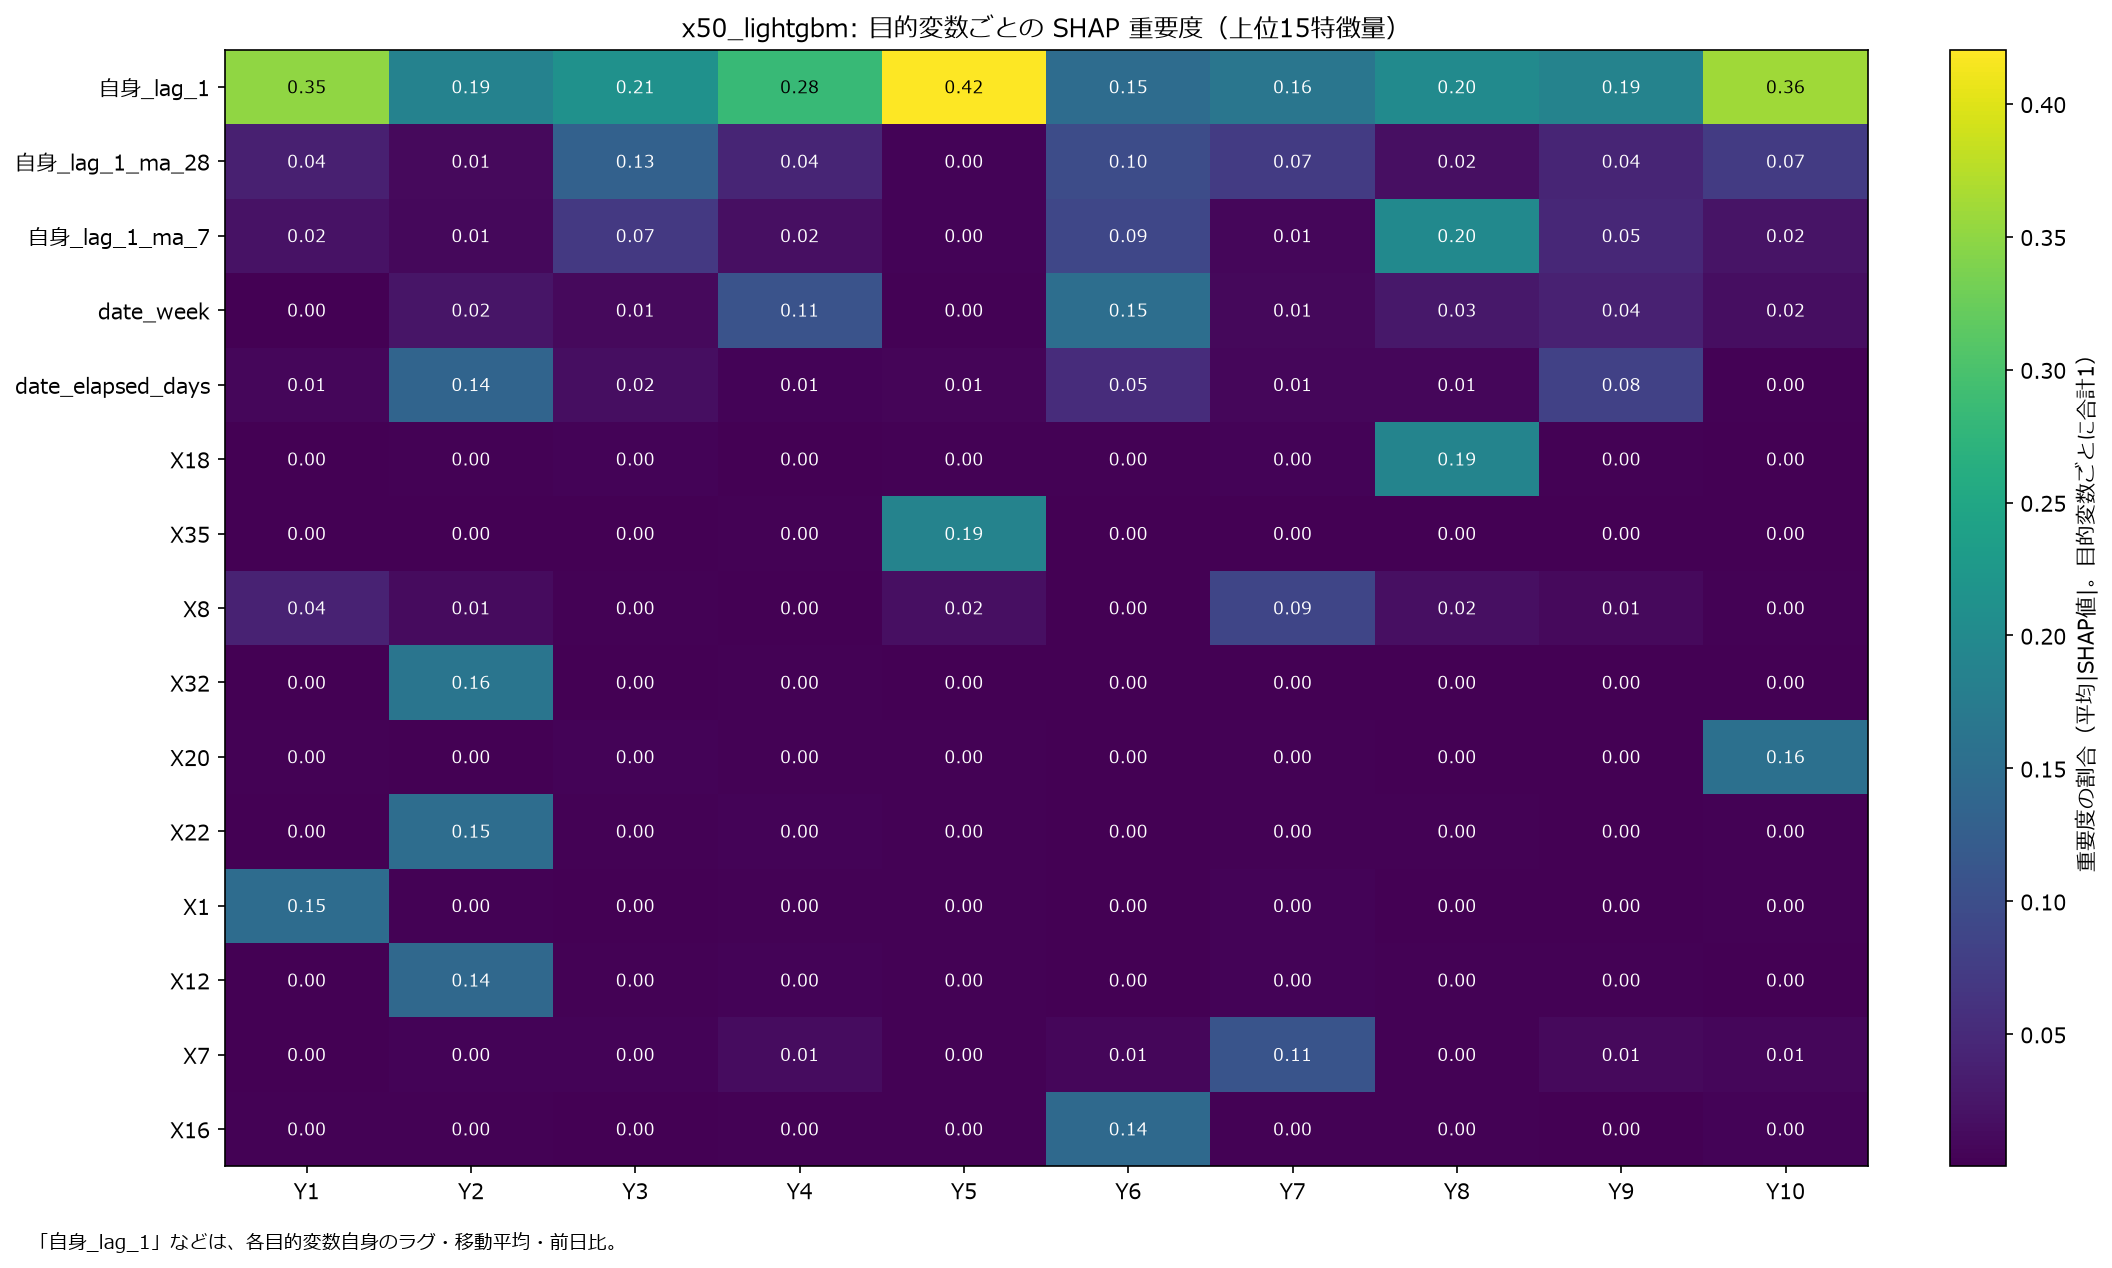

In [15]:
display(Image(filename=str(figures / "shap_overview.png"), width=800))

## 5. 1つの目的変数の詳細（`DETAIL_TARGET`）

### 学習結果

- **学習期間の実測値と検証期間の再帰予測:** 各 fold の検証期間（網掛け）を、実測値を使わずに予測した結果。
- **予測ステップ別の MAE:** 検証期間の何日目の予測かごとの MAE。先の日ほど誤差が積み重なる。
- **学習の推移:** 木の本数ごとの学習・検証の損失（対数の尺度）。

Y1: outputs/experiments/x50_lightgbm_Y1/20261021_221128_273772


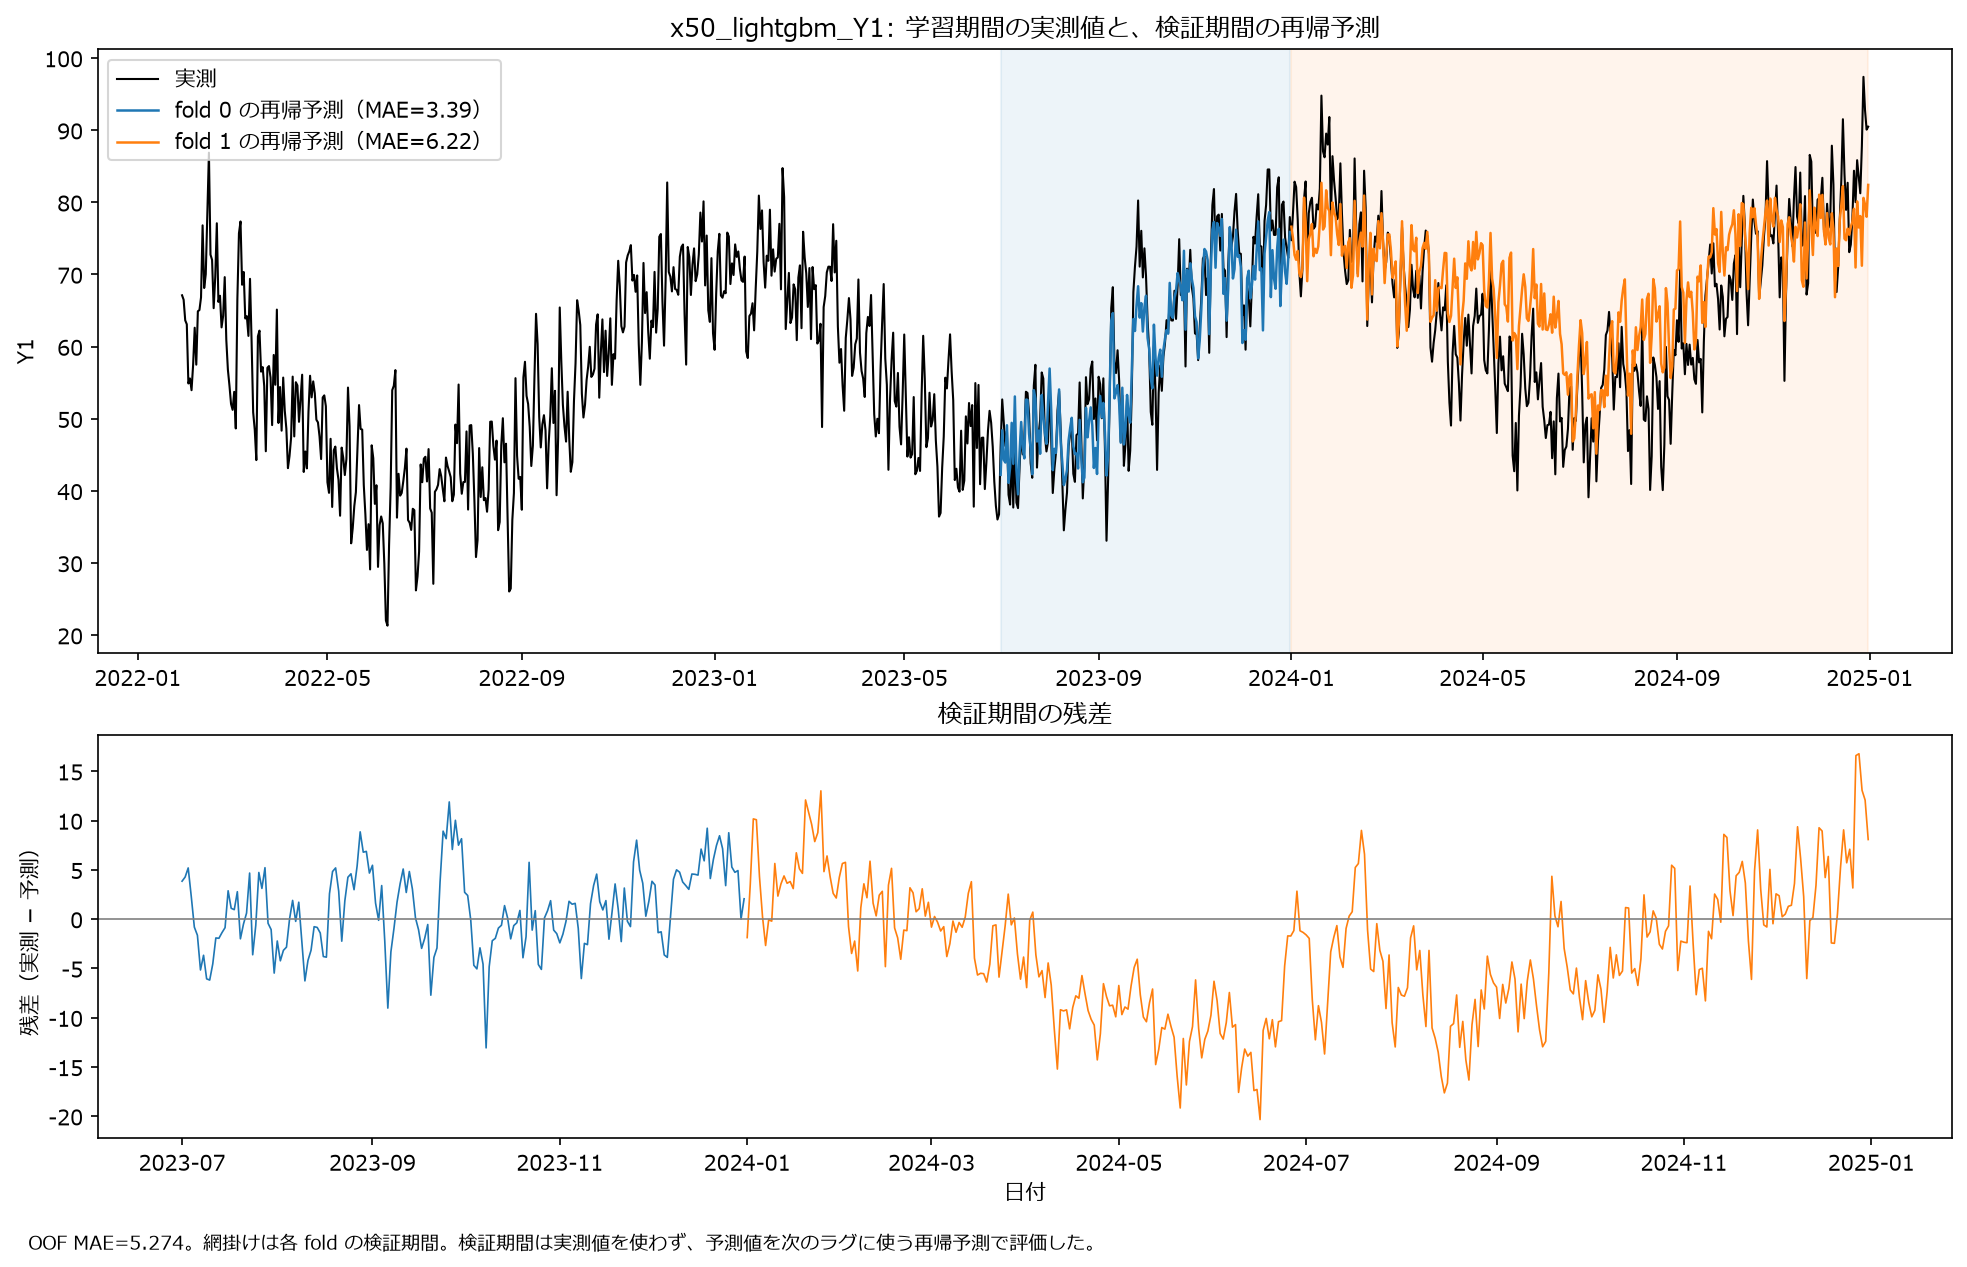

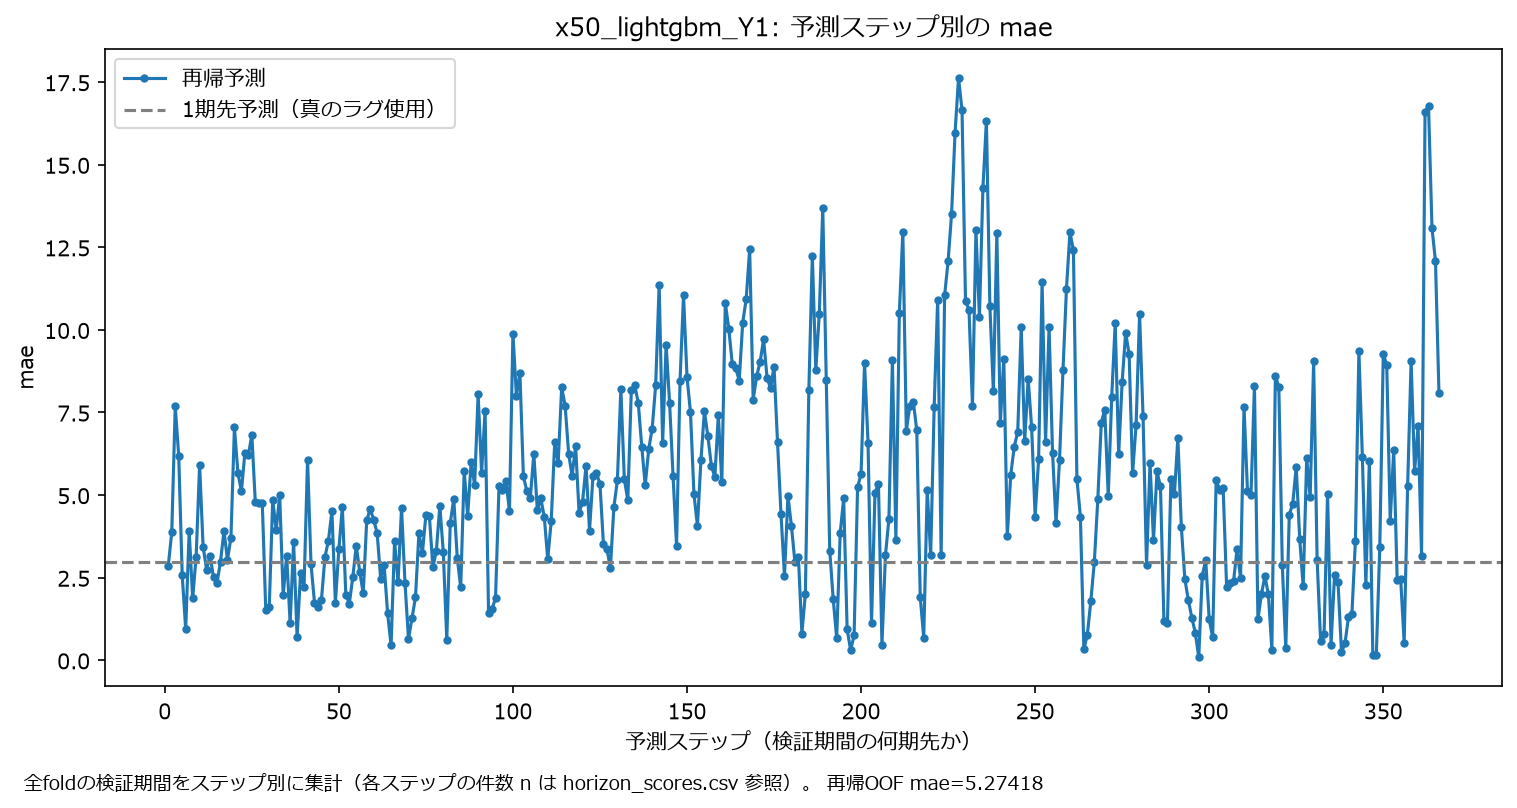

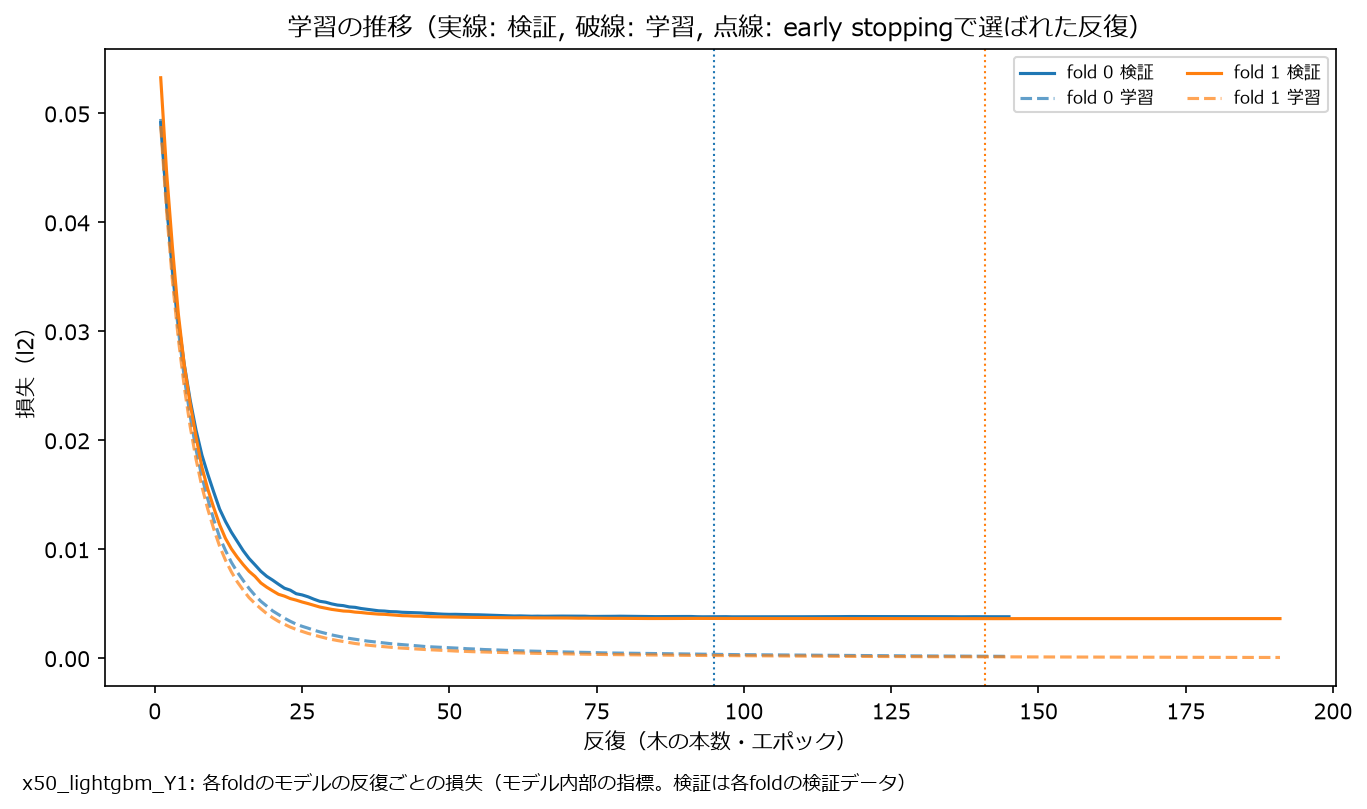

In [16]:
detail = next(run for run in runs if run.target == DETAIL_TARGET)
out = detail.result.output_dir
print(f"{DETAIL_TARGET}: {shown(out)}")
display(Image(filename=str(out / "figures" / "training_result.png"), width=1000))
display(Image(filename=str(out / "horizon_error.png"), width=800))
display(Image(filename=str(out / "evaluation" / "training_history.png"), width=800))

検証期間の残差の診断（`modeling.evaluation` が作る図）。残差に偏り・自己相関が残っていないかを見る。

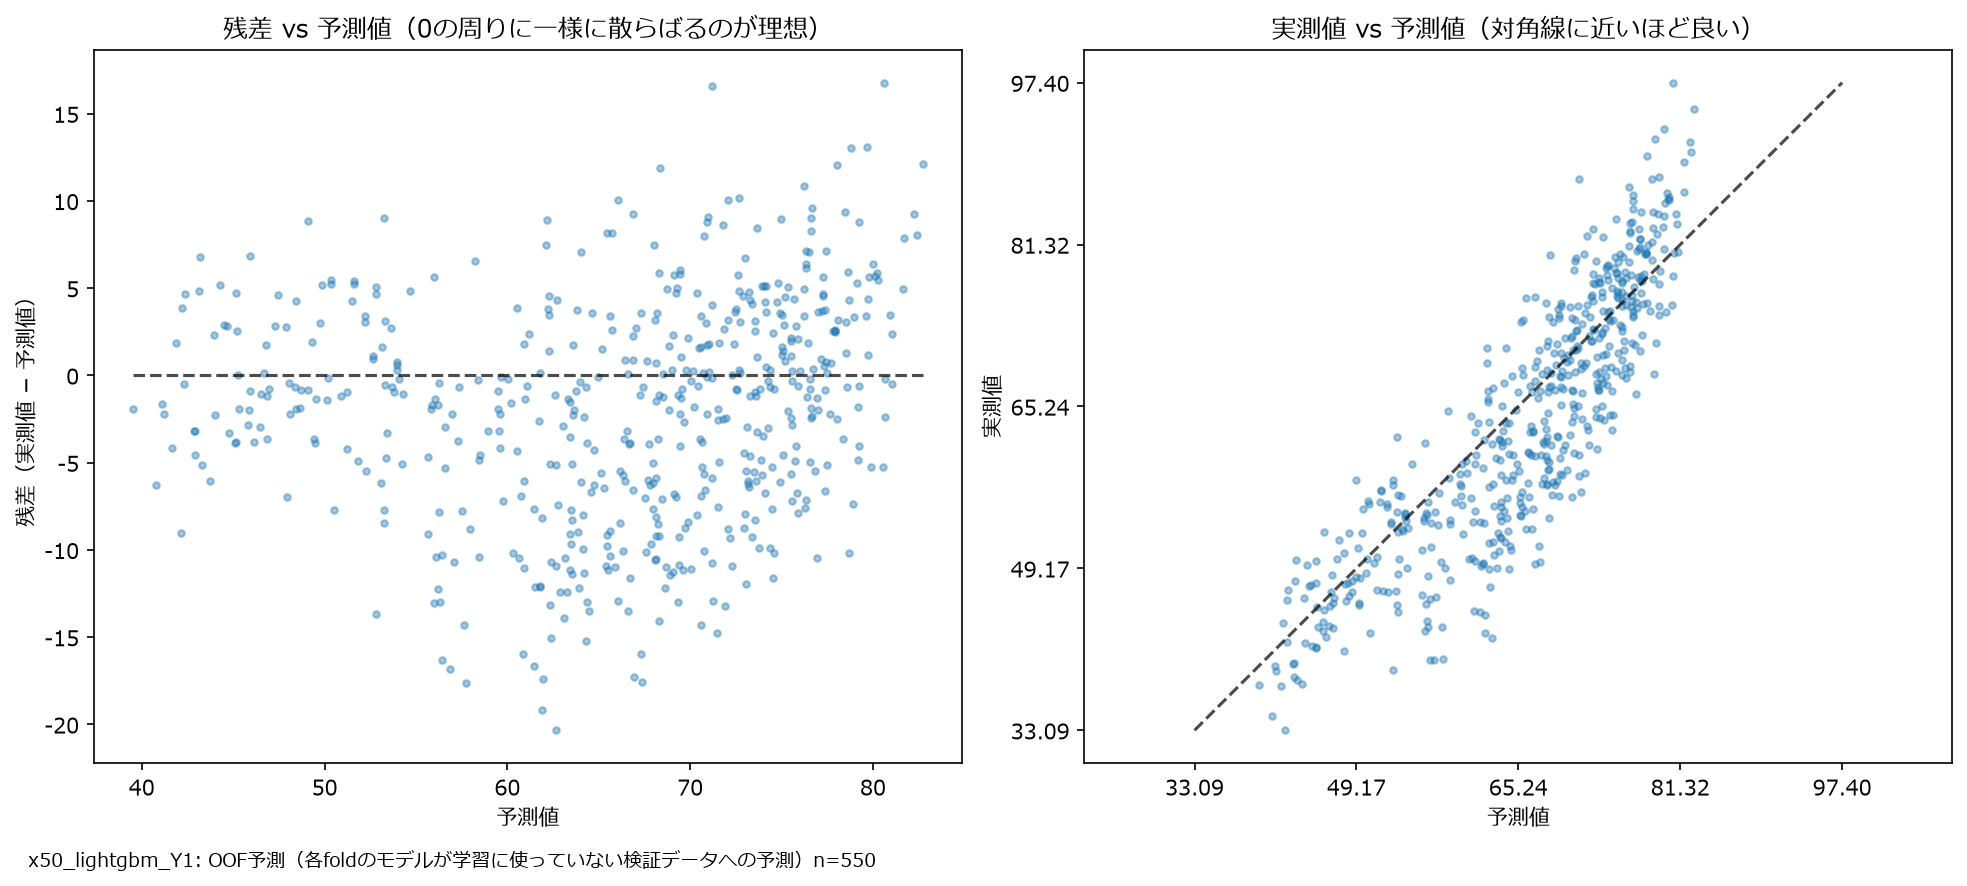

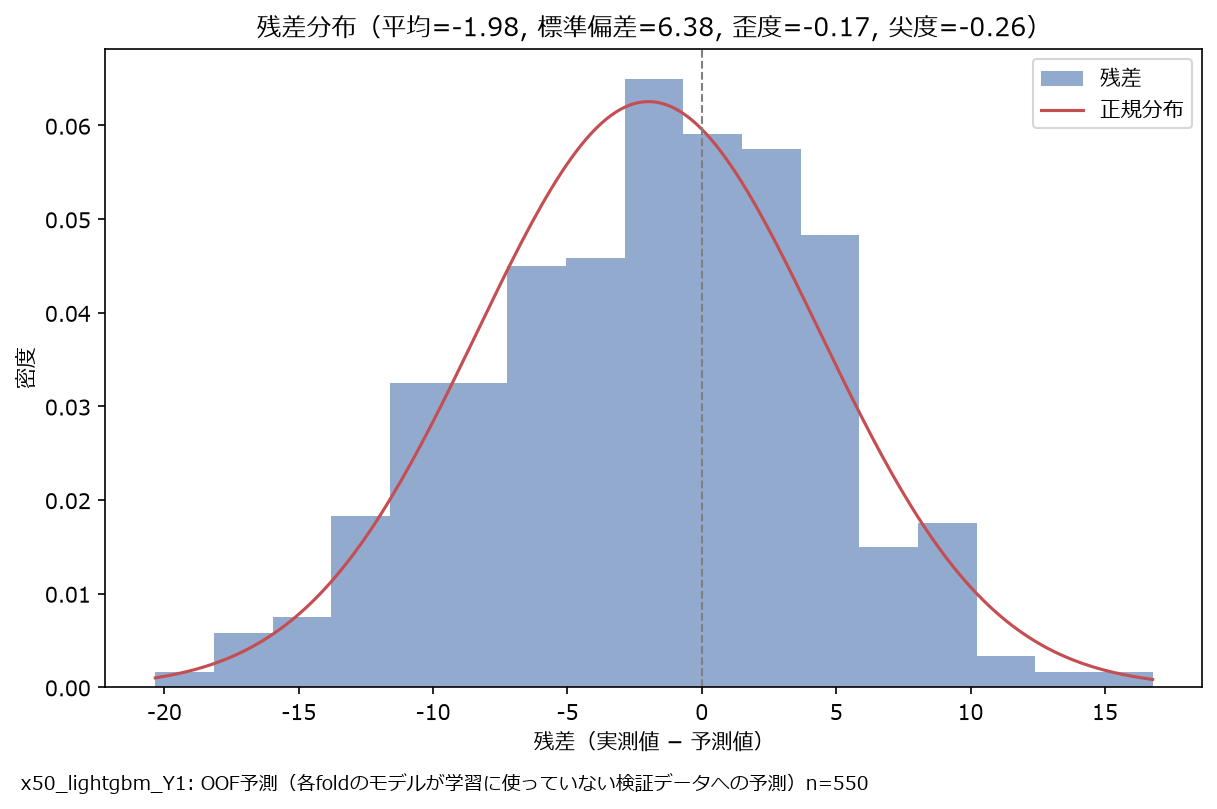

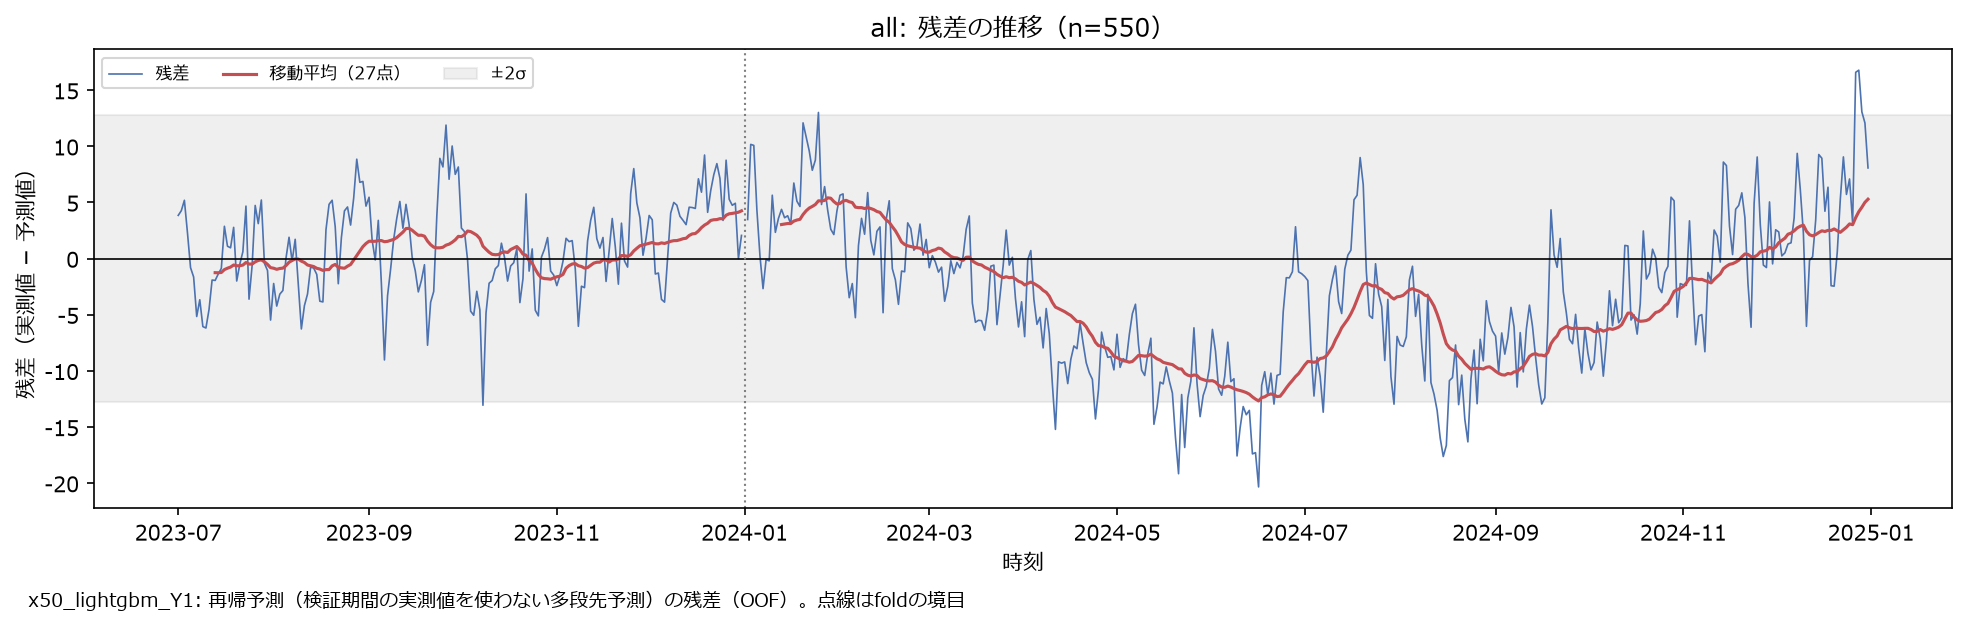

In [17]:
for name in ("residual_plot.png", "residual_distribution.png", "residual_timeseries.png"):
    display(Image(filename=str(out / "evaluation" / name), width=850))

### テスト結果

テスト期間（2025年）の再帰予測と実測値、予測と実測の散布図、月別の MAE。

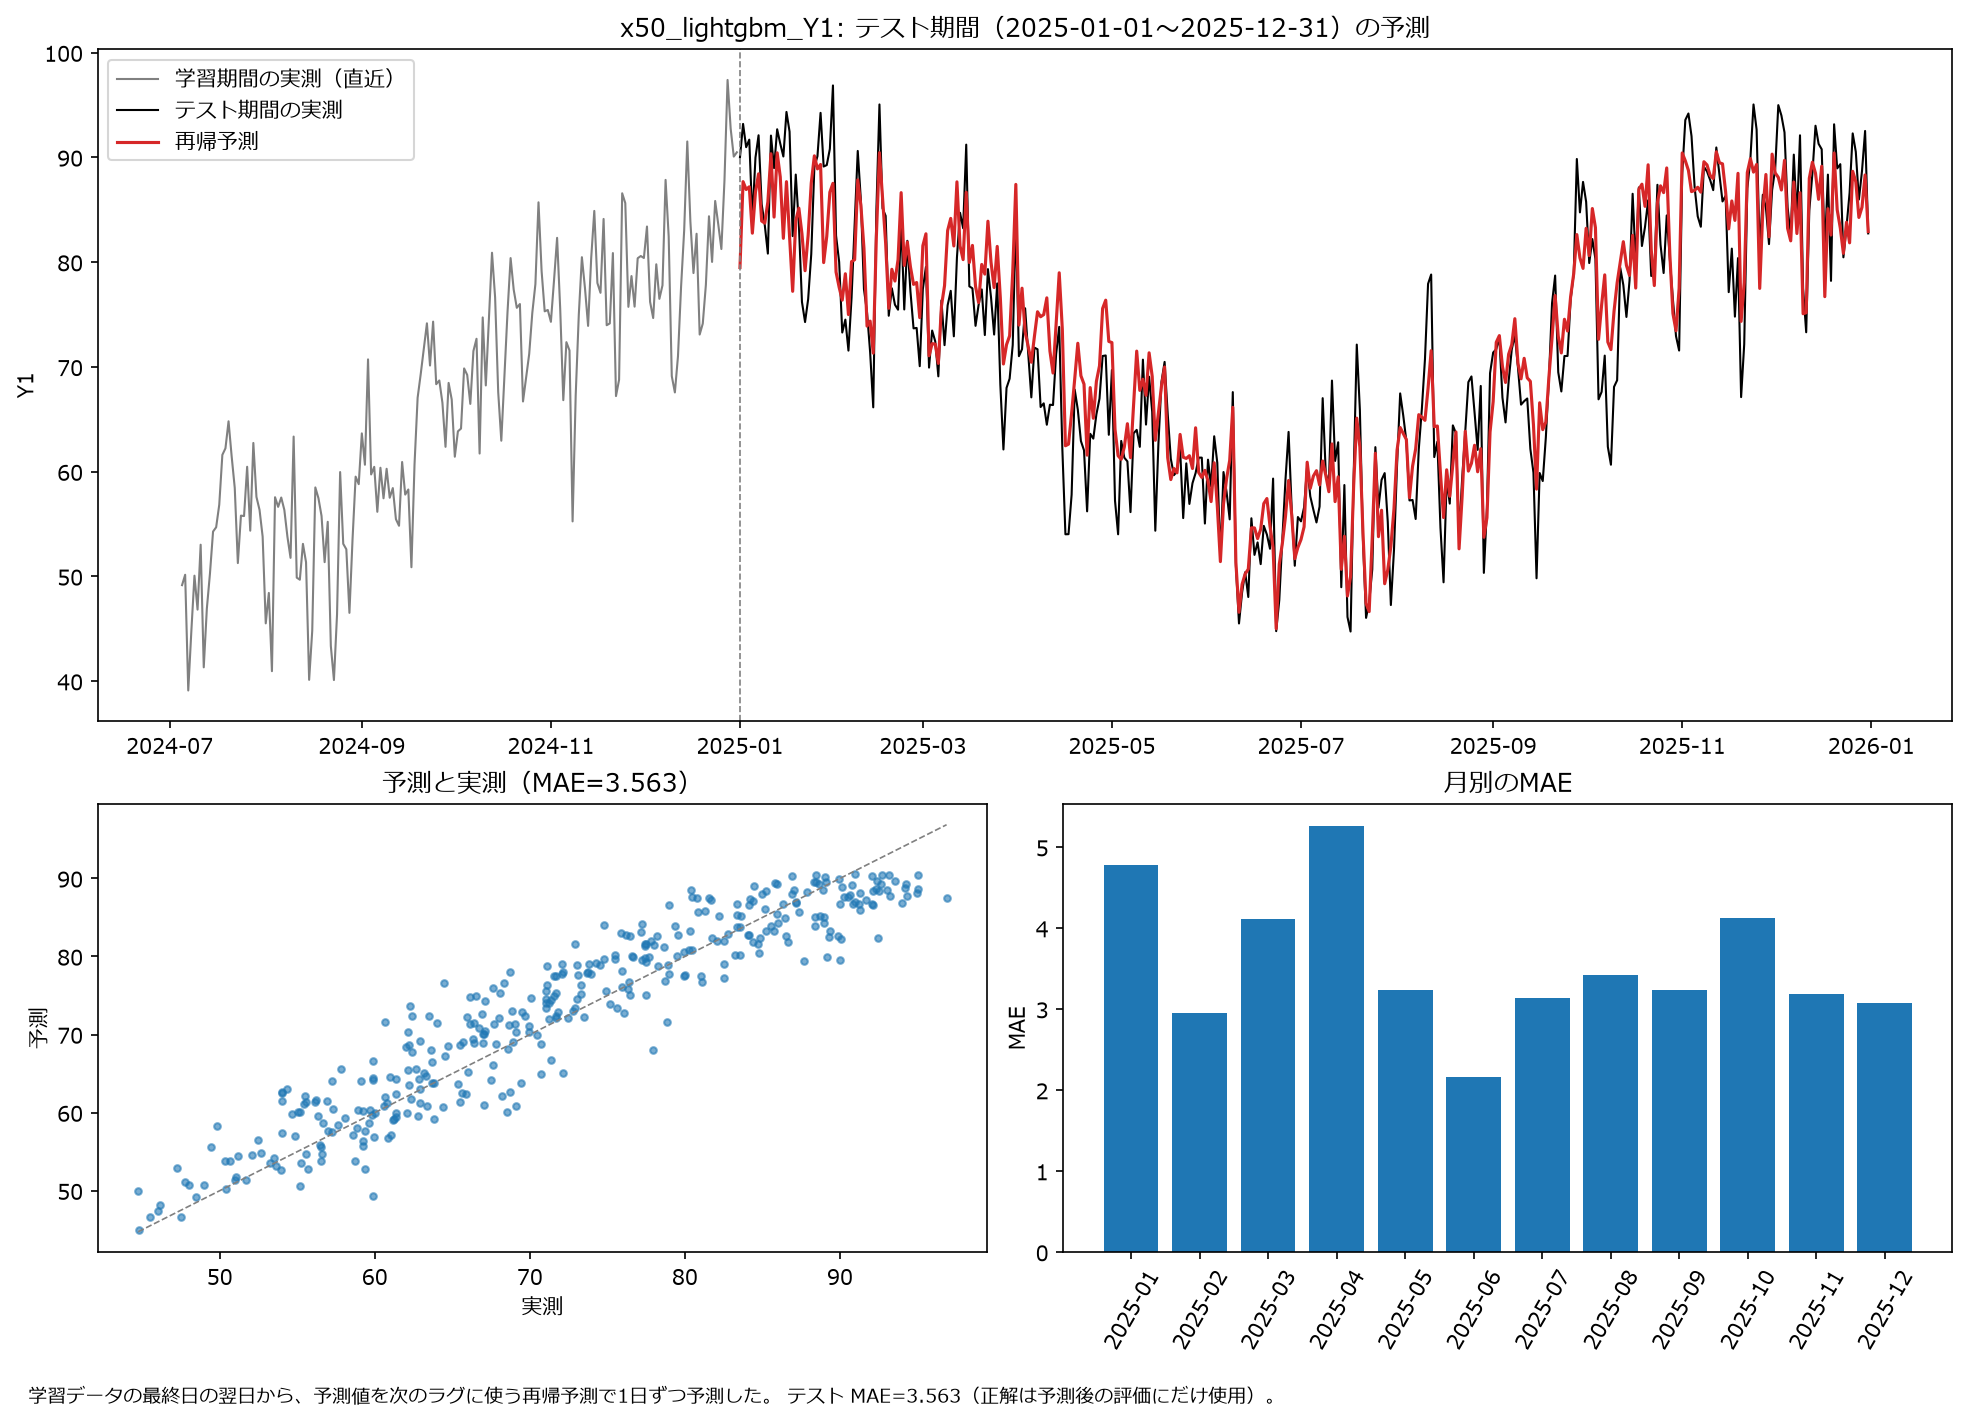

In [18]:
display(Image(filename=str(out / "figures" / "test_result.png"), width=1000))

### SHAP によるモデル解釈

各 fold のモデルを、その検証期間のデータで説明した SHAP 値（OOF SHAP）。モデルは目的変数の対数を予測するため、
SHAP 値も対数の尺度（例: 0.01 は予測値を約1%押し上げる）。

- **重要度:** 平均 |SHAP 値| の大きい特徴量ほど予測への影響が大きい。
- **beeswarm:** 各点が1日。色は特徴量の値（赤=大きい）、横軸は予測への寄与。
- **効きの向き:** 特徴量の値が大きいほど予測を押し上げる（赤）か、押し下げる（青）か。
- **依存関係:** 上位の特徴量の値と SHAP 値の関係。

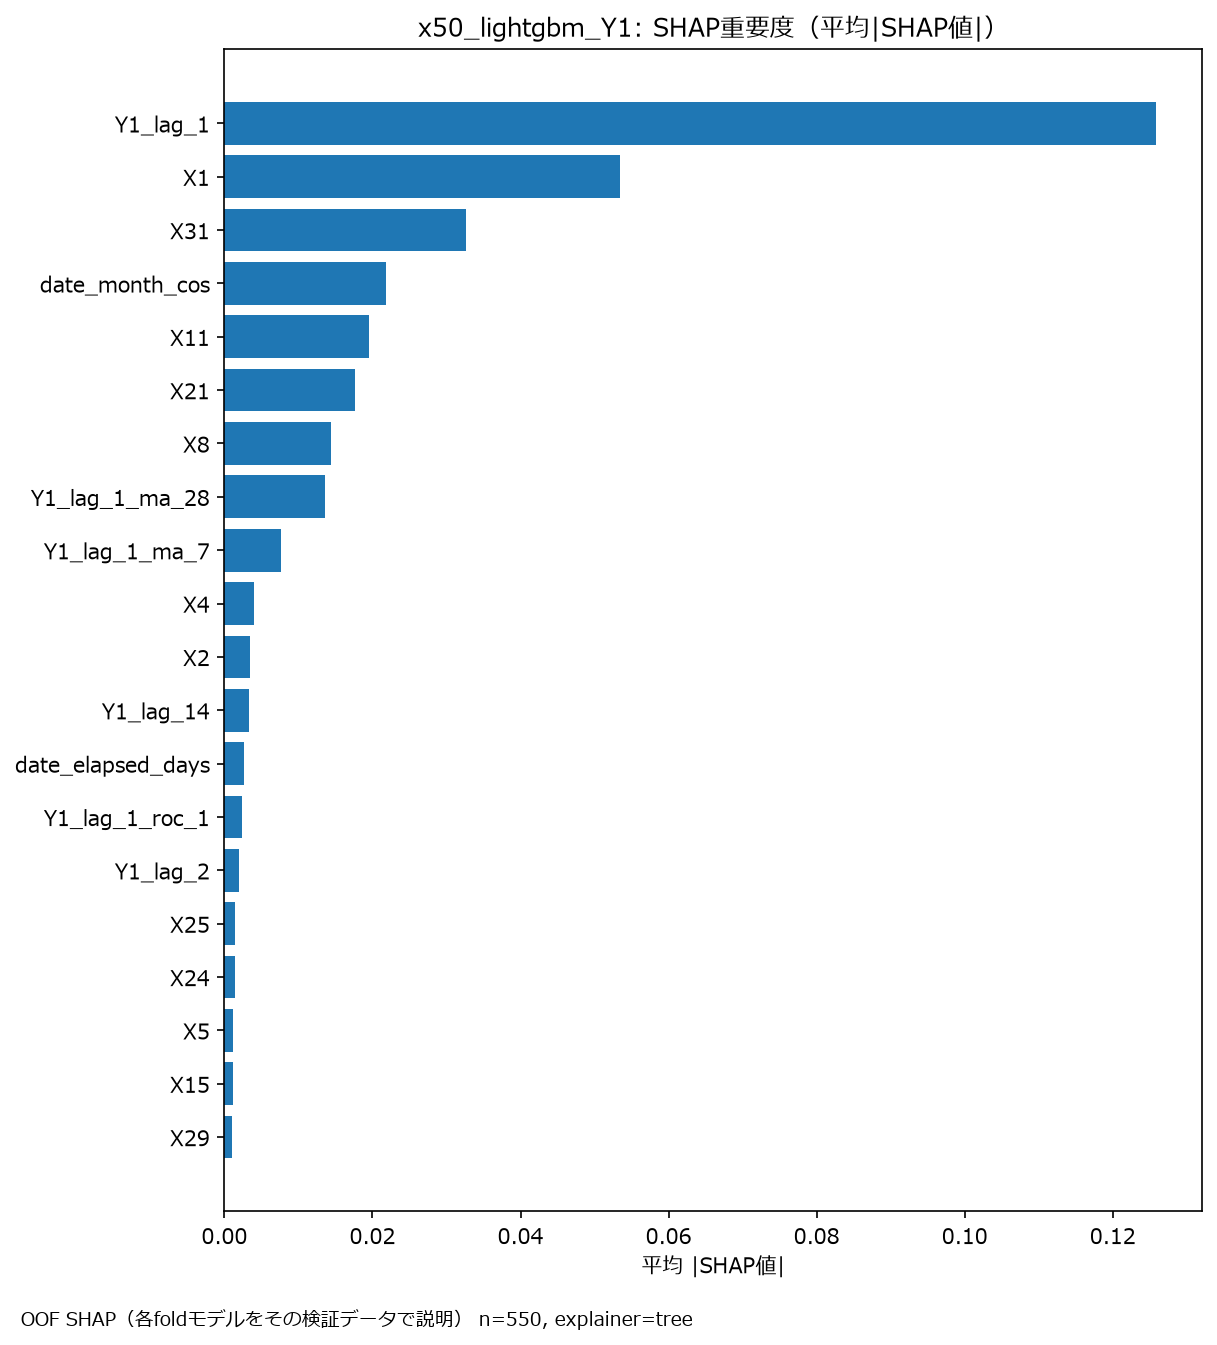

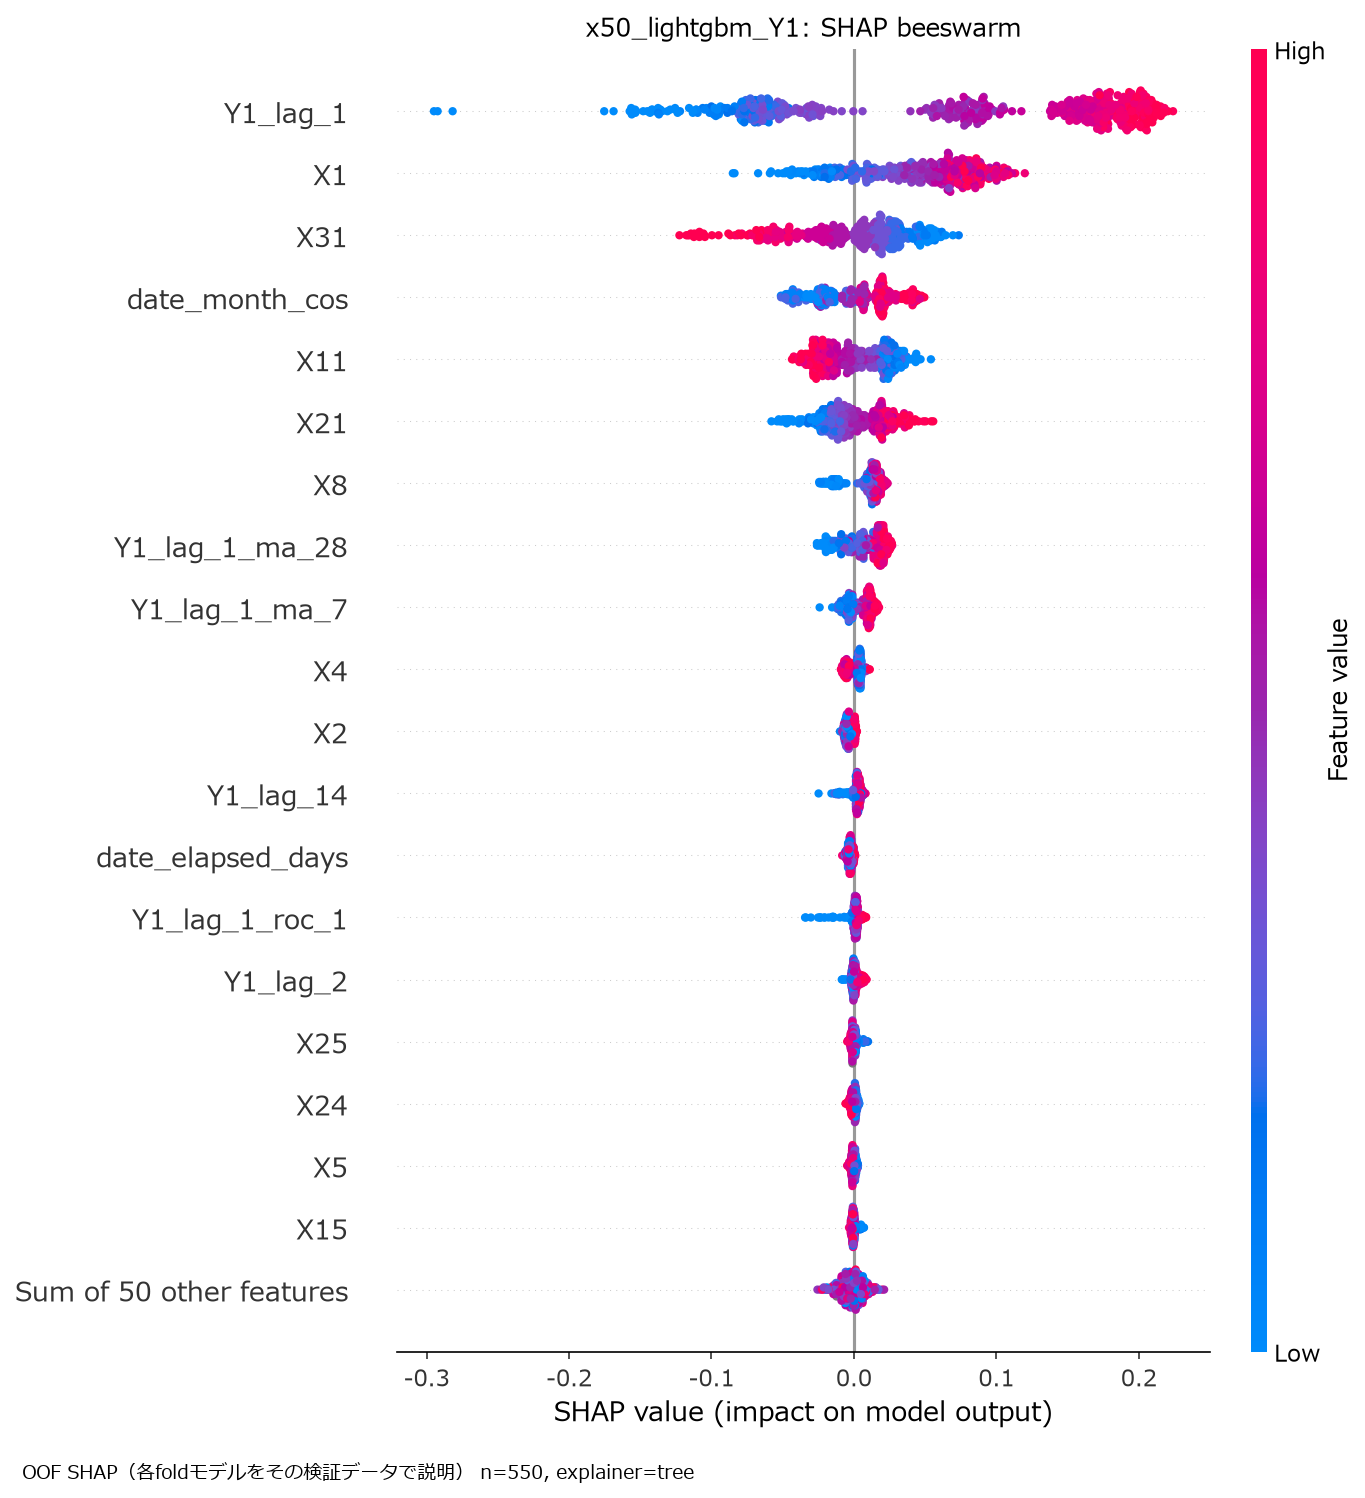

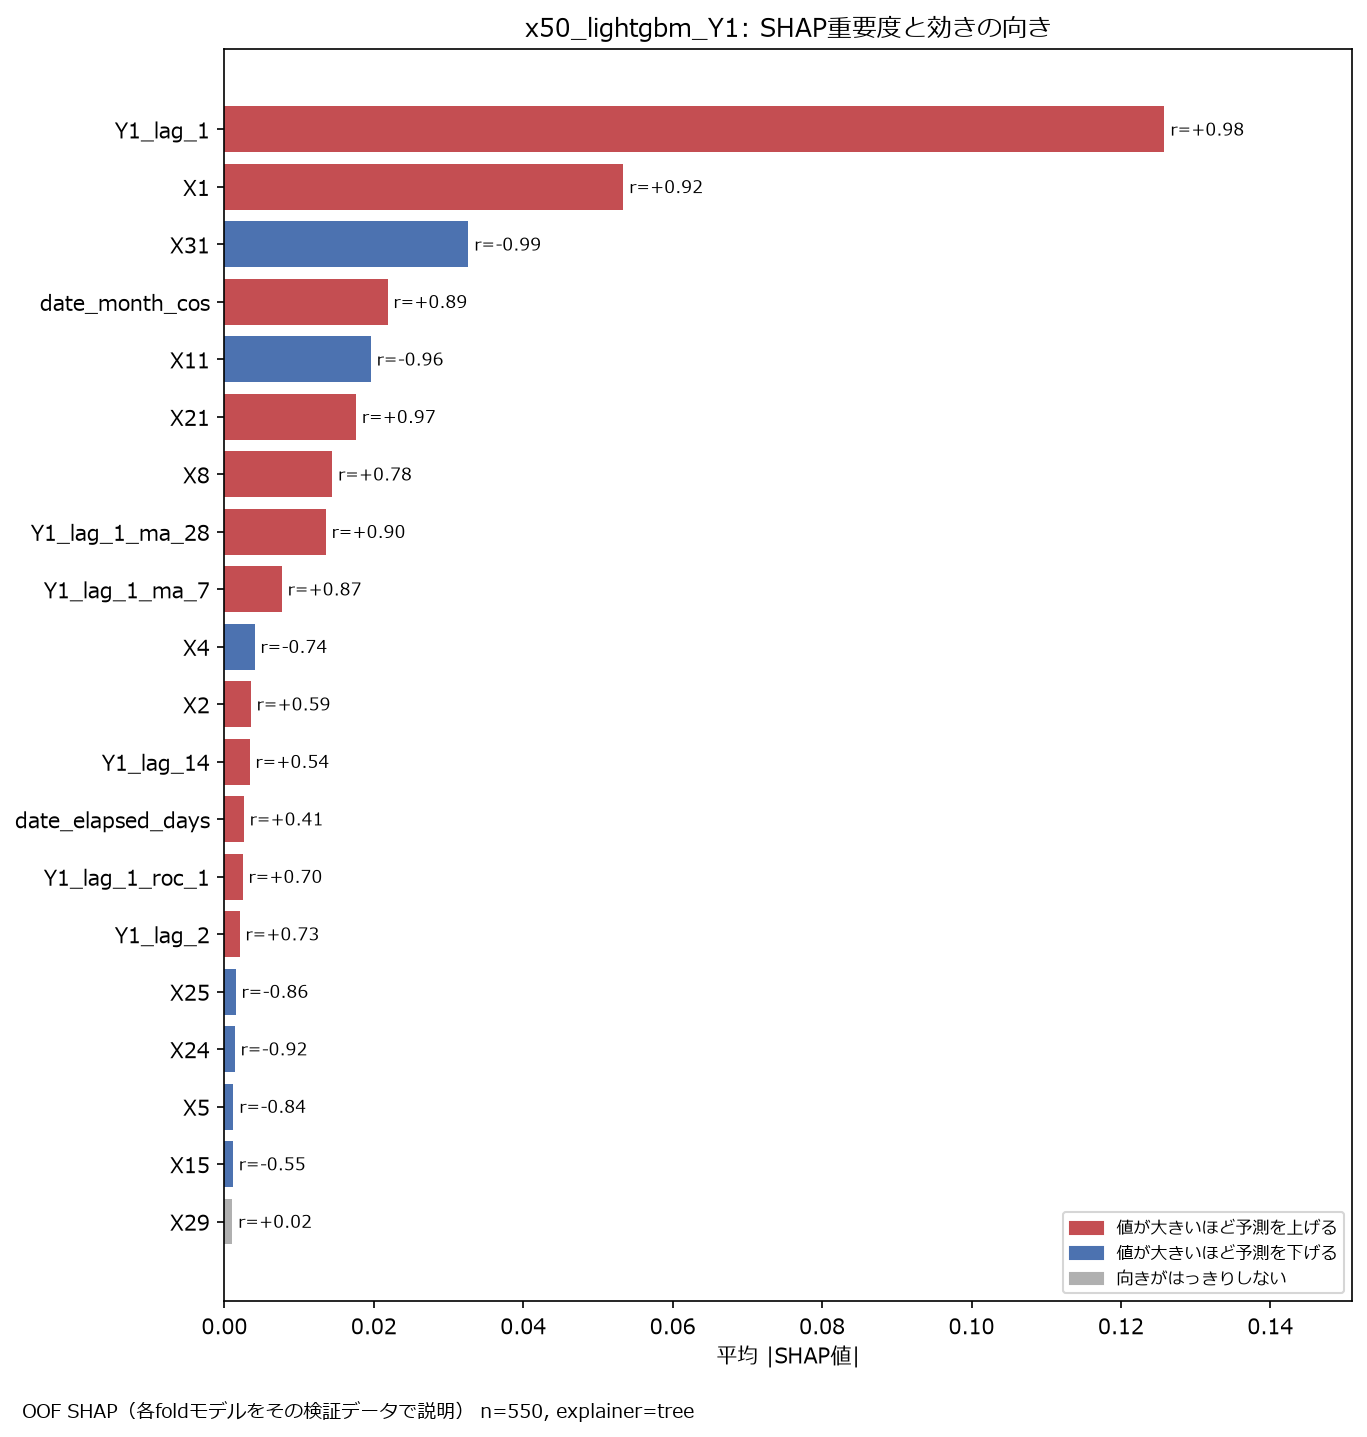

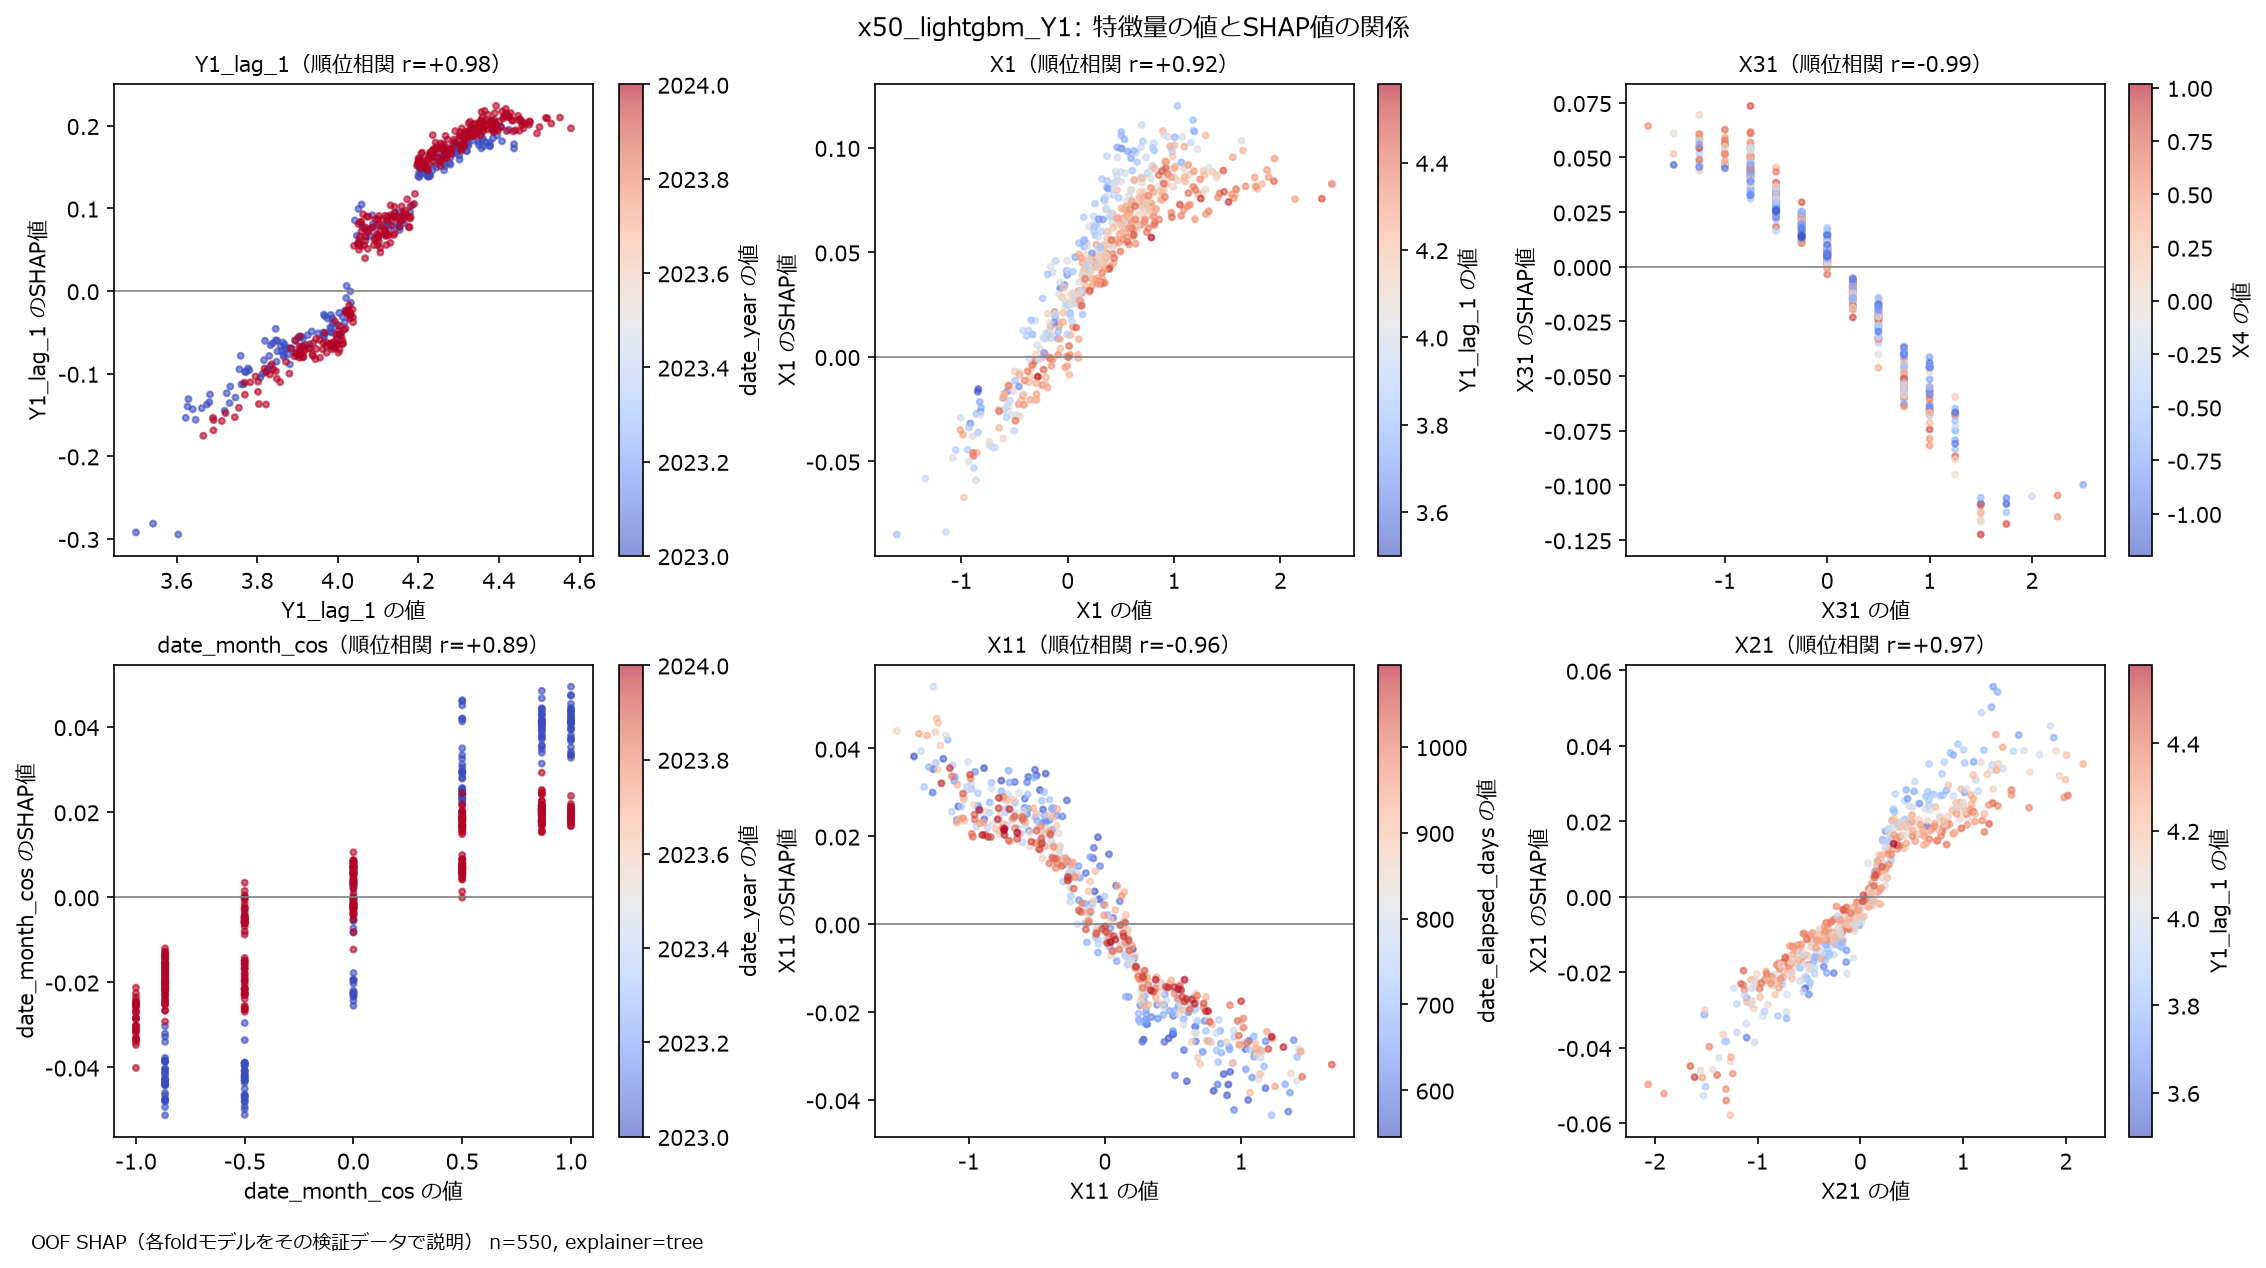

In [19]:
shap_dir = out / "shap"
display(Image(filename=str(shap_dir / "shap_importance_bar.png"), width=700))
display(Image(filename=str(shap_dir / "shap_beeswarm.png"), width=800))
display(Image(filename=str(shap_dir / "shap_correlation_bar.png"), width=800))
display(Image(filename=str(shap_dir / "shap_dependence.png"), width=1000))

## まとめ

- 目的変数 Y1〜Y10 ごとに選んだモデルを学習し、2025年を再帰予測した。目的変数のラグ・移動平均は、検証・テスト期間では
  予測値から作り直している。各モデルは自分自身のラグだけを使い、他の目的変数の値は使わない。
- CV は本番と同じ条件（検証期間の実測値を使わない再帰予測）で評価しているため、CV の MAE とテストの MAE を比べて、
  過学習や期間による違いを確認できる。
- ログはファイル（`outputs/logs/`、要約ディレクトリの `run.log`）と MLflow（目的変数ごとの run と要約の run。
  同じ `batch` タグで結び付く）に残している。

**注意点**

- 目的変数ごとに水準が違うため、目的変数をまたいで比べるときは相対MAE を使う。
- トレンドのある目的変数（ダミーでは Y3・Y6・Y9）は、テスト期間に学習範囲より高い水準になる。木のモデルは学習範囲の
  外へ外挿できないため、テストの誤差が CV より大きくなりやすい（差分の変換などを検討する）。
- SHAP は検証期間（OOF）での説明。テスト期間のモデル（学習データ全体で学習し直したもの）とは、学習に使った期間が違う。